# TCC — Análise comparativa de algoritmos de ML para detecção de ataques em redes IoT (IoT-23)

**Aluno:** Murilo Kaemmerer Klein · **Orientador:** Prof. Marco Antonio Sandini Trentin

Este notebook segue a ordem das etapas da proposta (Seção 4.2).

| Seção | Etapa da proposta | Status |
|---|---|---|
| 1 | Configuração do ambiente | ✅ |
| 2 | Etapa 1 — Seleção, pré-processamento e análise exploratória | ✅ |
| 3 | Etapa 2 — Divisão treino/teste, normalização e balanceamento | ✅ |
| 4 | Etapa 3 — Implementação dos modelos (RF, AD, SVM, CNN) | ✅ |
| 5 | Etapa 4 — Ajuste de hiperparâmetros | SVM ✅ · CNN ✅ · RF/AD ✅ |
| 6 | Etapa 5 — Avaliação e comparação (McNemar como teste principal) + importância de atributos | ✅ |
| 7 | Experimentos complementares (validade — Seção 4.4) | ✅ (LOSO com os 4 modelos) |
| 8 | Experimento: representação das portas (árvores sem portas · CNN com portas categóricas) | ✅ |

**Como rodar:** execute de cima para baixo (*Runtime → Run all*), **com GPU** (*Runtime → Change runtime type → T4 GPU*). As etapas caras usam *cache* no Drive:
- o carregamento dos logs brutos (~8 GB de RAM) só roda se `REPROCESSAR_DADOS_BRUTOS = True` ou se o checkpoint amostrado não existir;
- os modelos SVM, o tuning e a validação cruzada do SVM ficam salvos no Drive e são recarregados;
- cada CNN treinada (Random Search e seeds) fica salva em `modelos/cnn/` — se a sessão cair, basta rodar de novo.

## 1. Configuração do ambiente

In [ ]:
# 1.1 — Imports (todos concentrados aqui)
import os, gc, json, time, hashlib, itertools, urllib.request
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # silencia logs internos do TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight
from sklearn.base import clone
from statsmodels.stats.contingency_tables import mcnemar

import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")   # oculta avisos inofensivos de 'retracing'
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "nenhuma (vai rodar na CPU, mais lento)")

TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 1.2 — Google Colab: Drive + repositório Git
from google.colab import userdata, drive

drive.mount('/content/drive')

token = userdata.get('GITHUB_TOKEN')
usuario = "muriloklein"
repo = "tcc"
if not os.path.exists("/content/tcc"):
    !git clone https://{token}@github.com/{usuario}/{repo}.git
%cd /content/tcc

# !git config --global user.email "eu.murilok@gmail.com"
# !git config --global user.name "Murilo Klein"
# !pip install imbalanced-learn --quiet

Mounted at /content/drive
Cloning into 'tcc'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (60/60), done.
remote: Total 91 (delta 37), reused 77 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (91/91), 629.47 KiB | 12.10 MiB/s, done.
Resolving deltas: 100% (37/37), done.
/content/tcc


In [ ]:
# 1.3 — Caminhos, constantes e flags (tudo que é "configuração" fica só aqui)
BASE_DIR      = "/content/drive/MyDrive/TCC"
DADOS_DIR     = f"{BASE_DIR}/dados/raw"                # logs brutos do IoT-23
PROCESSED_DIR = f"{BASE_DIR}/dados/processed"          # checkpoints parquet + scaler
FIGURAS_DIR   = f"{BASE_DIR}/resultados/figuras"       # figuras para o texto
TABELAS_DIR   = f"{BASE_DIR}/resultados/tabelas"       # CSVs de resultados para o texto
MODELOS_DIR   = f"{BASE_DIR}/modelos"                  # cache de modelos e hiperparâmetros
PRED_DIR      = f"{BASE_DIR}/resultados/predicoes"     # cache de predições no teste
CV_DIR        = f"{BASE_DIR}/resultados/cv_svm"        # cache da CV do SVM (por fold)
CNN_DIR       = f"{MODELOS_DIR}/cnn"                   # cache das CNNs (Random Search + seeds)
LOSO_DIR      = f"{BASE_DIR}/resultados/loso"          # cache das predições do leave-one-scenario-out
for d in (DADOS_DIR, PROCESSED_DIR, FIGURAS_DIR, TABELAS_DIR, MODELOS_DIR, PRED_DIR, CV_DIR, CNN_DIR, LOSO_DIR):
    os.makedirs(d, exist_ok=True)

# Checkpoints
CAMINHO_BRUTO     = f"{PROCESSED_DIR}/dataset_completo_bruto_v1.parquet"   # tudo, antes da dedup
CAMINHO_AMOSTRADO = f"{PROCESSED_DIR}/dataset_amostrado_v1.parquet"        # após dedup + teto por classe
CAMINHO_ENCODED   = f"{PROCESSED_DIR}/dataset_encoded_v1.parquet"          # após limpeza + one-hot

# Parâmetros do experimento
RANDOM_STATE     = 42
CAP_POR_CLASSE   = 20_000      # teto de linhas únicas por classe
CLASSES_SEM_TETO = {"benign"}  # o benigno entra inteiro
LIMIAR_HISTORY   = 500         # categorias de 'history' com menos ocorrências viram "outros"
TEST_SIZE        = 0.30

# Flags de execução
REPROCESSAR_DADOS_BRUTOS = False   # True = recarrega os 21 mi de linhas brutas (lento, ~8 GB RAM)
RETREINAR_SVM            = False   # True = ignora o cache dos SVMs e treina de novo (horas)
RETREINAR_CNN            = False   # True = ignora o cache das CNNs
RETREINAR_ARVORES        = False   # True = refaz o Grid Search do RF e da AD
RETREINAR_LOSO           = False   # True = refaz todas as rodadas do leave-one-scenario-out
LOSO_SVM_MULTICLASSE     = False   # True = inclui o SVM também no LOSO multiclasse (+~45 min)

# Colunas
COLUNAS_NUMERICAS   = ["id.orig_p", "id.resp_p", "duration", "orig_bytes",
                       "resp_bytes", "missed_bytes", "orig_pkts", "resp_pkts"]
COLUNAS_ONEHOT      = ["proto", "service", "conn_state", "history"]
COLUNAS_NAO_FEATURE = ["label", "detailed-label", "origem_cenario"]   # alvos + metadado
COLUNAS_PORTA       = ["id.resp_p", "id.orig_p"]                       # usadas no experimento da Seção 8
PORTAS_LIMIAR       = 500    # Seção 8: portas com >= 500 ocorrências no treino viram categoria própria

RF_KWARGS = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

# CNN
CNN_FORMATO    = (6, 7)       # 42 atributos -> matriz 6x7 (zero-padding automático se faltar atributo)
CNN_VALIDACAO  = 0.20         # holdout de validação, retirado do TREINO (o teste não é tocado)
CNN_EPOCAS_MAX = 150          # teto alto: com 50, várias configurações não convergiam
CNN_PACIENCIA  = 10           # tolera oscilações da val_loss antes de parar
CNN_N_CONFIGS  = 8            # nº de configurações do Random Search (por tarefa)
CNN_SEEDS      = [42, 7, 123, 2024, 31415]   # 5 execuções independentes do modelo final

In [ ]:
# 1.4 — Funções utilitárias (reutilizadas em todo o notebook)

def rotulo_multiclasse(detailed_label):
    """Benignos têm detailed-label vazio: vira 'benign'."""
    return detailed_label.astype("string").fillna("benign")


def salvar_figura(nome_arquivo):
    plt.savefig(os.path.join(FIGURAS_DIR, nome_arquivo), dpi=300, bbox_inches="tight")


def salvar_tabela(df, nome_arquivo):
    caminho = os.path.join(TABELAS_DIR, nome_arquivo)
    df.to_csv(caminho, index=False)
    print(f"[tabela] {caminho}")


# ---------- Pré-processamento (fonte única: usado no pipeline principal E nos experimentos) ----------
def tratar_ausentes(df):
    df = df.copy()
    df = df.drop(columns=["local_orig", "local_resp"])            # 100% vazias
    for col in ["duration", "orig_bytes", "resp_bytes"]:
        df[f"{col}_ausente"] = df[col].isna()                     # indicador antes de preencher
    df[["duration", "orig_bytes", "resp_bytes"]] = df[["duration", "orig_bytes", "resp_bytes"]].fillna(0)
    for col in ["service", "history"]:
        if df[col].dtype.name == "category":
            df[col] = df[col].cat.add_categories(["desconhecido"])
        df[col] = df[col].fillna("desconhecido")
    return df


def reduzir_e_codificar(df, categorias_history=None):
    """Remove redundantes, agrupa 'history' raros e aplica one-hot.
    categorias_history=None -> aprende as categorias frequentes com os próprios dados.
    Passe uma lista para reaproveitar o vocabulário de outro conjunto (ex.: teste externo)."""
    df = df.drop(columns=["resp_ip_bytes", "orig_ip_bytes"])      # correlação ~1 com resp/orig_bytes
    if categorias_history is None:
        contagem = df["history"].value_counts()
        categorias_history = [str(c) for c in contagem[contagem >= LIMIAR_HISTORY].index]
    df["history"] = df["history"].astype("string")
    df["history"] = df["history"].where(df["history"].isin(categorias_history), "outros")
    df_enc = pd.get_dummies(df, columns=COLUNAS_ONEHOT, prefix=COLUNAS_ONEHOT, dtype="int8")
    return df_enc, categorias_history


def preprocessar_features(df, categorias_history=None):
    return reduzir_e_codificar(tratar_ausentes(df), categorias_history)


def separar_X_y(df_enc):
    X = df_enc.drop(columns=[c for c in COLUNAS_NAO_FEATURE if c in df_enc.columns])
    return X, df_enc["label"], rotulo_multiclasse(df_enc["detailed-label"])


def normalizar(X_tr, X_te, colunas=COLUNAS_NUMERICAS):
    """StandardScaler só nas colunas numéricas; fit no treino, transform no teste."""
    scaler = StandardScaler()
    X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
    X_tr_n[colunas] = scaler.fit_transform(X_tr[colunas])
    X_te_n[colunas] = scaler.transform(X_te[colunas])
    return X_tr_n, X_te_n, scaler


def sobreposicao(X_tr, X_te):
    """Quantas linhas do teste têm vetor de features idêntico a alguma linha do treino (via hash)."""
    hashes_treino = set(pd.util.hash_pandas_object(X_tr, index=False))
    no_treino = pd.util.hash_pandas_object(X_te, index=False).isin(hashes_treino)
    return int(no_treino.sum()), float(no_treino.mean() * 100)


# ---------- Treino / avaliação ----------
def treinar_avaliar(titulo, modelo, X_tr, y_tr, X_te, y_te, nome_cache=None, retreinar=False):
    """Treina, prediz no teste e imprime o classification_report.
    Com nome_cache: salva/recarrega modelo e predições no Drive (usado nos SVMs, que levam horas).
    Retorna (modelo, y_pred, tempo_treino_s)."""
    y_pred = None
    if nome_cache:
        caminho_modelo = f"{MODELOS_DIR}/{nome_cache}.joblib"
        caminho_pred   = f"{PRED_DIR}/{nome_cache}_pred.npy"

    if nome_cache and os.path.exists(caminho_modelo) and not retreinar:
        salvo = joblib.load(caminho_modelo)
        modelo, tempo_treino = salvo["modelo"], salvo["tempo_treino"]
        print(f"[cache] modelo carregado: {caminho_modelo}")
        if getattr(modelo, "n_features_in_", X_te.shape[1]) != X_te.shape[1]:
            raise RuntimeError(f"{nome_cache}: modelo em cache espera {modelo.n_features_in_} features, "
                               f"mas X tem {X_te.shape[1]}. Os dados mudaram — use retreinar=True.")
    else:
        t0 = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo_treino = time.perf_counter() - t0
        if nome_cache:
            joblib.dump({"modelo": modelo, "tempo_treino": tempo_treino}, caminho_modelo)
            if os.path.exists(caminho_pred):
                os.remove(caminho_pred)          # predição antiga não vale mais

    if nome_cache and os.path.exists(caminho_pred):
        y_pred = np.load(caminho_pred)
        # Checagem de consistência: o cache precisa corresponder ao conjunto de teste ATUAL
        n = min(50, len(X_te))
        if len(y_pred) != len(y_te) or not np.array_equal(
                np.asarray(modelo.predict(X_te.iloc[:n]), dtype=str), y_pred[:n]):
            raise RuntimeError(f"{nome_cache}: predições em cache não batem com o teste atual. "
                               "Os dados mudaram — use retreinar=True.")
    else:
        y_pred = np.asarray(modelo.predict(X_te), dtype=str)
        if nome_cache:
            np.save(caminho_pred, y_pred)

    print(f"\n=== {titulo} === (treino: {tempo_treino:.2f}s)")
    print(classification_report(y_te, y_pred, digits=4, zero_division=0))
    return modelo, y_pred, tempo_treino


def plotar_matriz_confusao(y_true, y_pred, labels, titulo, nome_arquivo):
    matriz = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(9, 7))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(titulo); plt.xlabel("Classe prevista"); plt.ylabel("Classe real")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    salvar_figura(nome_arquivo)
    plt.show()
    return matriz


def subamostra_estratificada(y, cap_padrao=3000, caps=None, seed=RANDOM_STATE):
    """Índices POSICIONAIS (.iloc). Classes pequenas entram inteiras; grandes são cortadas."""
    rng = np.random.default_rng(seed)
    y_arr = np.asarray(y.astype(str))
    caps = caps or {}
    partes = []
    for classe in np.unique(y_arr):
        pos = np.where(y_arr == classe)[0]
        n = min(len(pos), caps.get(classe, cap_padrao))
        partes.append(rng.choice(pos, size=n, replace=False))
    return np.sort(np.concatenate(partes))


# ---------- Acesso ao checkpoint bruto (experimentos da Seção 7) ----------
def contar_classes_bruto(caminho=CAMINHO_BRUTO):
    """Contagem REAL de linhas por classe no dataset bruto (substitui contagens digitadas à mão)."""
    col = ds.dataset(caminho, format="parquet").to_table(columns=["detailed-label"]) \
            .column("detailed-label").to_pandas()
    vc = col.value_counts(dropna=False)
    return {("benign" if pd.isna(k) else str(k)): int(v) for k, v in vc.items() if v > 0}


def amostrar_classe_bruto(dataset, classe, p_manter, rng):
    """Amostragem de Bernoulli de uma classe, lendo o parquet em lotes (não estoura a RAM)."""
    filtro = pc.field("detailed-label").is_null() if classe == "benign" \
             else (pc.field("detailed-label") == classe)
    lotes = []
    for lote in dataset.to_batches(filter=filtro, batch_size=200_000):
        if lote.num_rows == 0:
            continue
        mascara = rng.random(lote.num_rows) < p_manter
        if mascara.any():
            lotes.append(lote.take(np.nonzero(mascara)[0]))
    return pa.Table.from_batches(lotes).to_pandas() if lotes else pd.DataFrame()

print("Ambiente pronto.")

Ambiente pronto.


## 2. Etapa 1 — Seleção e pré-processamento dos dados

Cenários do IoT-23 usados (9 capturas): 6 maliciosos (34-1, 36-1, 9-1, 8-1, 3-1, 1-1) e 3 benignos (Honeypot 4-1, 5-1, 7-1).

Ordem do pipeline:
1. download → 2. carregamento → 3. **deduplicação por classe e depois** teto de 20.000 linhas/classe →
4. valores ausentes → 5. análise exploratória → 6. remoção de redundantes, agrupamento de `history` e one-hot.

In [ ]:
# 2.1 — Download dos conn.log.labeled (pula os que já existem no Drive)
URL_BASE = "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/IndividualScenarios"

# A ORDEM deste dicionário é a ordem de concatenação — não altere, pois ela define
# qual linha é mantida na deduplicação (keep="first") e, portanto, a amostra final.
CENARIOS = {
    "capture_34_1_DDoS_PortScan":       f"{URL_BASE}/CTU-IoT-Malware-Capture-34-1/bro/conn.log.labeled",
    "capture_36_1_Okiru":               f"{URL_BASE}/CTU-IoT-Malware-Capture-36-1/bro/conn.log.labeled",
    "capture_9_1_PortScan":             f"{URL_BASE}/CTU-IoT-Malware-Capture-9-1/bro/conn.log.labeled",
    "capture_4_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-4-1/bro/conn.log.labeled",
    "capture_5_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-5-1/bro/conn.log.labeled",
    "capture_7_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-7-1/Somfy-01/bro/conn.log.labeled",
    "capture_8_1_CC_Hakai":             f"{URL_BASE}/CTU-IoT-Malware-Capture-8-1/bro/conn.log.labeled",
    "capture_3_1_Attack_Muhstik":       f"{URL_BASE}/CTU-IoT-Malware-Capture-3-1/bro/conn.log.labeled",
    "capture_1_1_PortScan_HideAndSeek": f"{URL_BASE}/CTU-IoT-Malware-Capture-1-1/bro/conn.log.labeled",
}
# Linhas descartadas por cenário (okiru-attack: rótulo residual do 36-1)
EXCLUIR_DETAILED_LABEL = {"capture_36_1_Okiru": "okiru-attack"}

def caminho_log(nome):
    return os.path.join(DADOS_DIR, f"{nome}.log.labeled")

for nome, url in CENARIOS.items():
    destino = caminho_log(nome)
    if os.path.exists(destino):
        print(f"[OK] {nome} já existe, pulando download.")
        continue
    print(f"Baixando {nome}...")
    try:
        urllib.request.urlretrieve(url, destino)
        print(f"[OK] {nome} salvo em {destino}")
    except Exception as e:
        print(f"[ERRO] Falha ao baixar {nome}: {e}")

PRECISA_PROCESSAR_BRUTO = REPROCESSAR_DADOS_BRUTOS or not os.path.exists(CAMINHO_AMOSTRADO)
print("\nProcessar dados brutos nesta execução?", PRECISA_PROCESSAR_BRUTO)

[OK] capture_34_1_DDoS_PortScan já existe, pulando download.
[OK] capture_36_1_Okiru já existe, pulando download.
[OK] capture_9_1_PortScan já existe, pulando download.
[OK] capture_4_1_Benign_Honeypot já existe, pulando download.
[OK] capture_5_1_Benign_Honeypot já existe, pulando download.
[OK] capture_7_1_Benign_Honeypot já existe, pulando download.
[OK] capture_8_1_CC_Hakai já existe, pulando download.
[OK] capture_3_1_Attack_Muhstik já existe, pulando download.
[OK] capture_1_1_PortScan_HideAndSeek já existe, pulando download.

Processar dados brutos nesta execução? False


In [ ]:
# 2.2 — Carregamento dos logs (só se necessário) + checkpoint bruto
# Nomes de coluna do conn.log do Zeek + as 2 colunas extras do IoT-23
COLUNAS_COMPLETAS = [
    "ts", "uid", "id.orig_h", "id.orig_p", "id.resp_h", "id.resp_p",
    "proto", "service", "duration", "orig_bytes", "resp_bytes",
    "conn_state", "local_orig", "local_resp", "missed_bytes",
    "history", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
    "tunnel_parents", "label", "detailed-label",
]
# Identificadores (ts, uid, IPs) e tunnel_parents não são carregados: evitam data leakage
COLUNAS_USADAS = [
    "id.orig_p", "id.resp_p", "proto", "service", "duration",
    "orig_bytes", "resp_bytes", "conn_state", "local_orig", "local_resp",
    "missed_bytes", "history", "orig_pkts", "orig_ip_bytes",
    "resp_pkts", "resp_ip_bytes", "label", "detailed-label",
]
DTYPE_OTIMIZADO = {   # 'category' e int32 reduzem drasticamente a RAM
    "proto": "category", "service": "category", "conn_state": "category",
    "local_orig": "category", "local_resp": "category", "history": "category",
    "label": "category", "detailed-label": "category",
    "id.orig_p": "int32", "id.resp_p": "int32", "missed_bytes": "int32",
    "orig_pkts": "int32", "orig_ip_bytes": "int32", "resp_pkts": "int32", "resp_ip_bytes": "int32",
}
CONFIG_LEITURA = {
    "sep": r"\s+",          # o header usa TAB, mas as últimas colunas às vezes vêm com espaço
    "comment": "#",         # ignora as linhas de cabeçalho do Zeek
    "header": None,
    "names": COLUNAS_COMPLETAS,
    "usecols": COLUNAS_USADAS,
    "na_values": "-",       # o Zeek usa "-" para ausente
    "dtype": DTYPE_OTIMIZADO,
}

def carregar_cenario(nome):
    df = pd.read_csv(caminho_log(nome), **CONFIG_LEITURA)
    df["label"] = df["label"].astype("string").str.lower().astype("category")
    df["detailed-label"] = df["detailed-label"].astype("string").str.lower().astype("category")
    if nome in EXCLUIR_DETAILED_LABEL:
        df = df[df["detailed-label"] != EXCLUIR_DETAILED_LABEL[nome]]
    origem = "_".join(nome.split("_")[:3])        # ex.: "capture_34_1"
    df["origem_cenario"] = origem
    print(f"{origem}: {df.shape} | {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB | "
          f"{df['label'].value_counts().to_dict()}")
    return df

if PRECISA_PROCESSAR_BRUTO:
    df_completo = pd.concat([carregar_cenario(n) for n in CENARIOS], ignore_index=True)
    gc.collect()
    # Checkpoint bruto (pré-dedup): usado nos experimentos de ablação da Seção 7
    df_completo.to_parquet(CAMINHO_BRUTO, index=False)
    print(f"\nCheckpoint bruto salvo em: {CAMINHO_BRUTO}")
    print(f"Formato: {df_completo.shape} | "
          f"{df_completo.memory_usage(deep=True).sum() / 1024**2:.0f} MB")
    print(df_completo["origem_cenario"].value_counts())
else:
    print("Checkpoint amostrado já existe — carregamento dos logs brutos pulado.")

Checkpoint amostrado já existe — carregamento dos logs brutos pulado.


In [ ]:
# 2.3 — Deduplicação por classe ANTES do teto de amostragem + checkpoint amostrado
# Por que nessa ordem: amostrar primeiro e deduplicar depois colapsava classes muito
# repetitivas (okiru: 621 combinações únicas em 13,6 mi de linhas brutas virava só 2
# numa amostra aleatória de 20 mil). Deduplicando antes, classes com menos linhas
# únicas que o teto entram inteiras.
if PRECISA_PROCESSAR_BRUTO:
    df_completo["classe_amostra"] = rotulo_multiclasse(df_completo["detailed-label"])
    colunas_para_dedup = [c for c in df_completo.columns
                          if c not in ["label", "detailed-label", "origem_cenario", "classe_amostra"]]

    grupos_amostrados, resumo_dedup = [], []
    for classe, grupo in df_completo.groupby("classe_amostra", observed=True):
        linhas_brutas = len(grupo)
        grupo = grupo.drop_duplicates(subset=colunas_para_dedup, keep="first")
        linhas_unicas = len(grupo)
        if classe not in CLASSES_SEM_TETO and linhas_unicas > CAP_POR_CLASSE:
            grupo = grupo.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)
        resumo_dedup.append({"classe": classe, "linhas_brutas": linhas_brutas,
                             "linhas_unicas": linhas_unicas, "linhas_amostradas": len(grupo)})
        grupos_amostrados.append(grupo)

    df_amostrado = pd.concat(grupos_amostrados, ignore_index=True).drop(columns=["classe_amostra"])
    del df_completo, grupos_amostrados
    gc.collect()

    df_resumo_dedup = pd.DataFrame(resumo_dedup)
    print(df_resumo_dedup.to_string(index=False))
    salvar_tabela(df_resumo_dedup, "resumo_dedup_por_classe.csv")
    df_amostrado.to_parquet(CAMINHO_AMOSTRADO, index=False)
    print(f"Checkpoint amostrado salvo em: {CAMINHO_AMOSTRADO}")

# Ponto de retomada: daqui para baixo tudo parte do checkpoint amostrado (leve, ~2 MB)
df_amostrado = pd.read_parquet(CAMINHO_AMOSTRADO)
print(f"\nDataset amostrado: {df_amostrado.shape}")
print(rotulo_multiclasse(df_amostrado["detailed-label"]).value_counts())


Dataset amostrado: (176859, 19)
detailed-label
benign                       123538
partofahorizontalportscan     20000
c&c-heartbeat                 15687
c&c                           10827
attack                         5962
okiru                           621
ddos                            224
Name: count, dtype: Int64


In [ ]:
# 2.4 — Valores ausentes
# - local_orig/local_resp: 100% vazias -> removidas
# - duration/orig_bytes/resp_bytes: indicador *_ausente + preenchimento com 0
# - service/history: categoria explícita "desconhecido"
df_limpo = tratar_ausentes(df_amostrado)
print(df_limpo.isna().sum()[lambda s: s > 0])   # só detailed-label (benignos) deve sobrar

detailed-label    123538
dtype: int64


### 2.5 — Análise exploratória

Feita **antes** de remover atributos, para que as decisões da etapa 2.6 (ex.: remoção de `orig_ip_bytes`/`resp_ip_bytes`) apareçam justificadas nos gráficos.

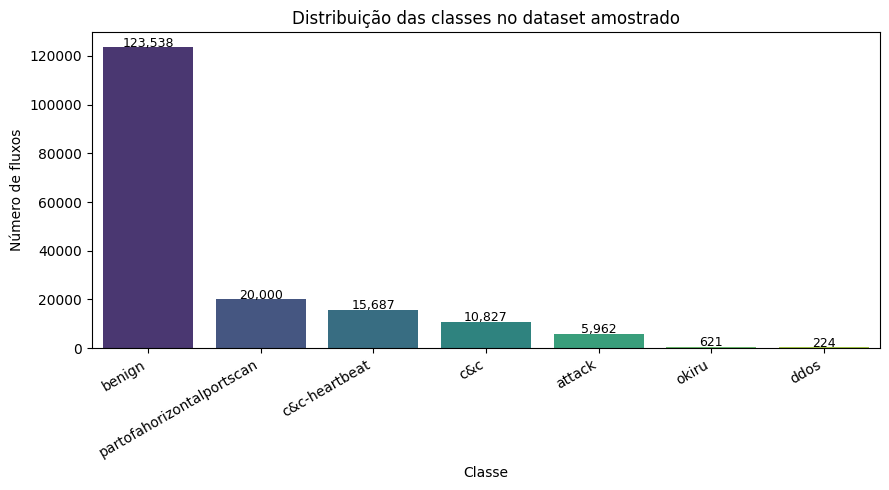

In [ ]:
# Gráfico 1 — Distribuição de classes
df_plot = df_limpo.copy()
df_plot["classe_plot"] = rotulo_multiclasse(df_plot["detailed-label"])
contagem_classes = df_plot["classe_plot"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=contagem_classes.index, y=contagem_classes.values,
            hue=contagem_classes.index, palette="viridis", legend=False)
plt.title("Distribuição das classes no dataset amostrado")
plt.xlabel("Classe"); plt.ylabel("Número de fluxos"); plt.xticks(rotation=30, ha="right")
for i, valor in enumerate(contagem_classes.values):
    plt.text(i, valor + 300, f"{valor:,}", ha="center", fontsize=9)
plt.tight_layout(); salvar_figura("distribuicao_classes.png"); plt.show()

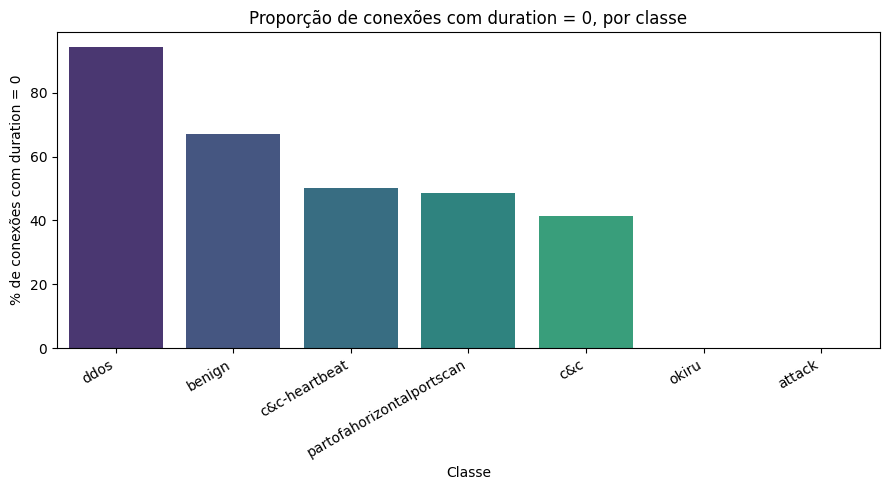

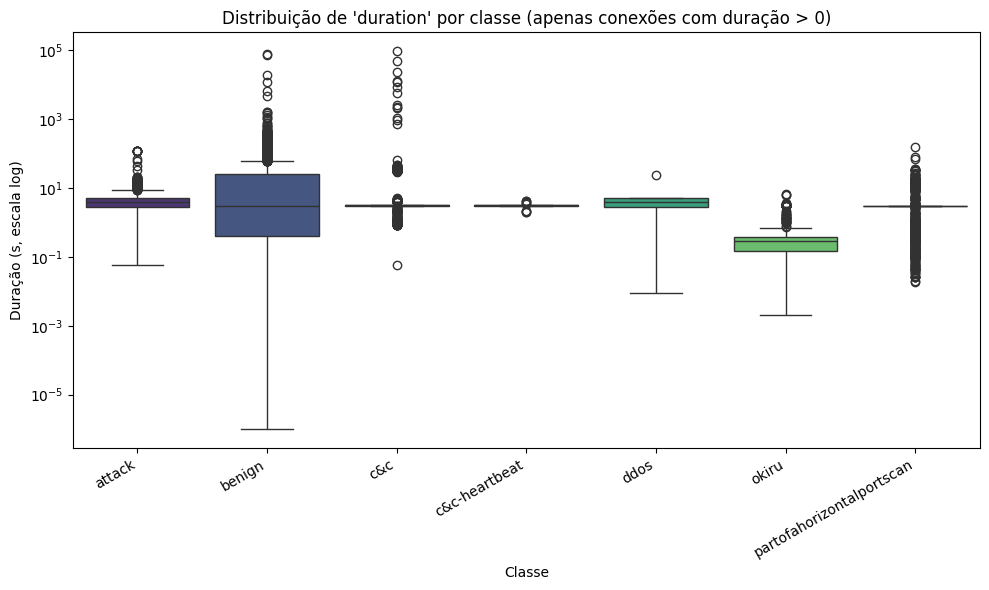

In [ ]:
# Gráfico 2a — Proporção de conexões "instantâneas" (duration = 0) por classe
proporcao_zero = (df_plot["duration"] == 0).groupby(df_plot["classe_plot"]).mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=proporcao_zero.index, y=proporcao_zero.values * 100,
            hue=proporcao_zero.index, palette="viridis", legend=False)
plt.title("Proporção de conexões com duration = 0, por classe")
plt.xlabel("Classe"); plt.ylabel("% de conexões com duration = 0"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); salvar_figura("proporcao_duration_zero.png"); plt.show()

# Gráfico 2b — duration por classe, só conexões com duração > 0
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_plot[df_plot["duration"] > 0], x="classe_plot", y="duration",
            hue="classe_plot", palette="viridis", legend=False)
plt.yscale("log")
plt.title("Distribuição de 'duration' por classe (apenas conexões com duração > 0)")
plt.xlabel("Classe"); plt.ylabel("Duração (s, escala log)"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); salvar_figura("duration_por_classe_sem_zeros.png"); plt.show()

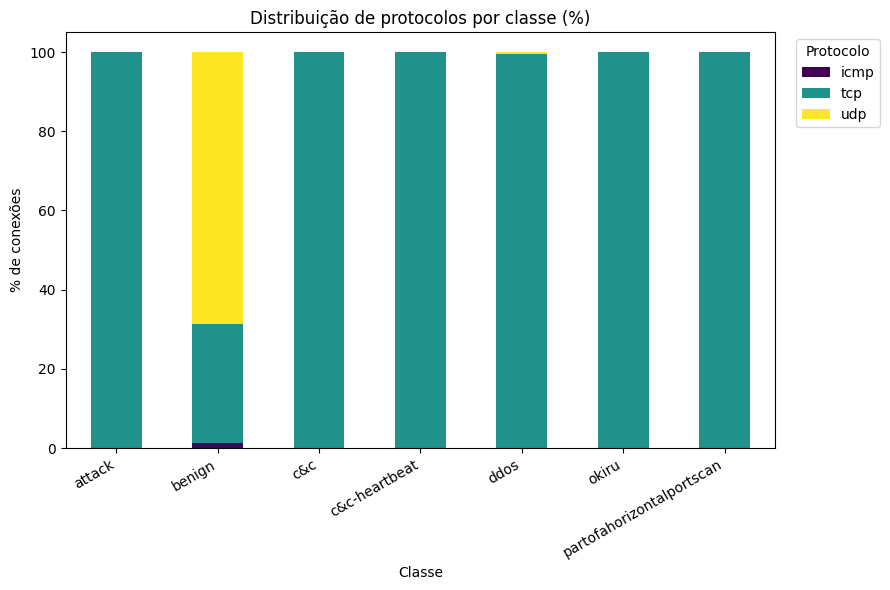

In [ ]:
# Gráfico 3 — Protocolos por classe
tabela_proto = pd.crosstab(df_plot["classe_plot"], df_plot["proto"], normalize="index") * 100
plt.figure(figsize=(9, 6))
tabela_proto.plot(kind="bar", stacked=True, colormap="viridis", ax=plt.gca())
plt.title("Distribuição de protocolos por classe (%)")
plt.xlabel("Classe"); plt.ylabel("% de conexões"); plt.xticks(rotation=30, ha="right")
plt.legend(title="Protocolo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); salvar_figura("protocolo_por_classe.png"); plt.show()

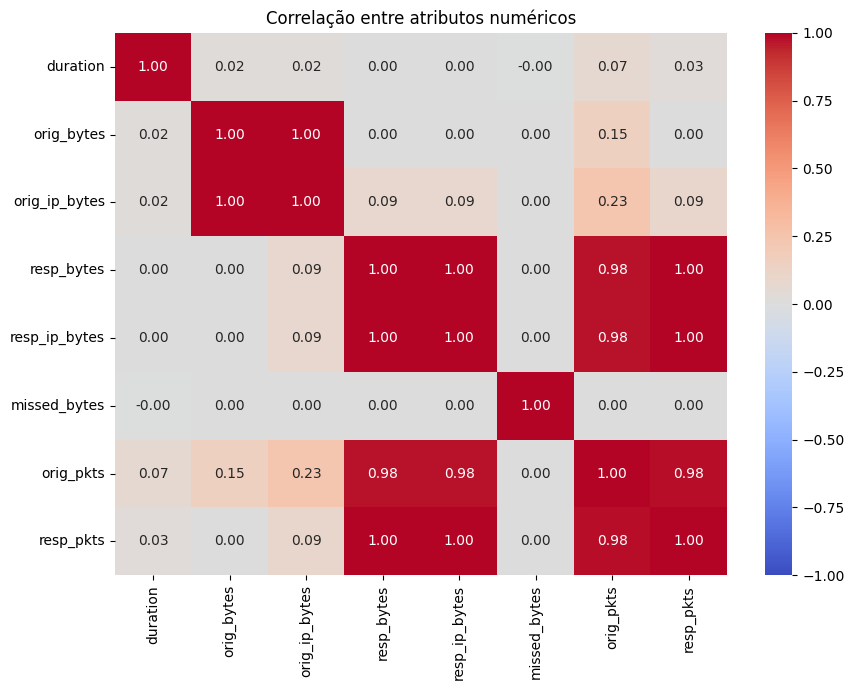

corr(orig_bytes, orig_ip_bytes) = 0.9963
corr(resp_bytes, resp_ip_bytes) = 1.0


In [ ]:
# Gráfico 4 — Correlação entre atributos numéricos (inclui *_ip_bytes, que serão removidos em 2.6)
colunas_corr = ["duration", "orig_bytes", "orig_ip_bytes", "resp_bytes", "resp_ip_bytes",
                "missed_bytes", "orig_pkts", "resp_pkts"]
matriz_corr = df_limpo[colunas_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre atributos numéricos")
plt.tight_layout(); salvar_figura("correlacao_numericos.png"); plt.show()

print("corr(orig_bytes, orig_ip_bytes) =", round(matriz_corr.loc["orig_bytes", "orig_ip_bytes"], 4))
print("corr(resp_bytes, resp_ip_bytes) =", round(matriz_corr.loc["resp_bytes", "resp_ip_bytes"], 4))
del df_plot

In [ ]:
# 2.6 — Remoção de redundantes + agrupamento de 'history' + one-hot  -> checkpoint encoded
df_encoded, CATEGORIAS_HISTORY = reduzir_e_codificar(df_limpo)

print(f"'history': {len(CATEGORIAS_HISTORY)} categorias mantidas (>= {LIMIAR_HISTORY} ocorrências): "
      f"{CATEGORIAS_HISTORY}; as demais viram 'outros'")
print(f"Formato: {df_limpo.shape} -> {df_encoded.shape}")

df_encoded.to_parquet(CAMINHO_ENCODED, index=False)
with open(f"{PROCESSED_DIR}/categorias_history_v1.json", "w") as f:   # vocabulário reaproveitável (ex.: CNN)
    json.dump(CATEGORIAS_HISTORY, f)
print(f"Checkpoint salvo em: {CAMINHO_ENCODED}")

'history': 7 categorias mantidas (>= 500 ocorrências): ['D', 'S', 'Sr', 'ShAdDaFf', 'Dd', 'desconhecido', 'ShAdDaf']; as demais viram 'outros'
Formato: (176859, 20) -> (176859, 45)
Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_encoded_v1.parquet


## 3. Etapa 2 — Divisão treino/teste, normalização e balanceamento

1. **Segunda deduplicação**, agora sobre o vetor final de features: a limpeza (preenchimento com 0, agrupamento de `history`, remoção de colunas) cria novas linhas idênticas, inclusive entre classes diferentes.
2. Split estratificado 70/30 (pelo rótulo multiclasse; o binário reaproveita os mesmos índices).
3. Normalização (fit só no treino).
4. Balanceamento: **SMOTE só na tarefa binária**; na multiclasse usa-se `class_weight='balanced'` (okiru/ddos têm pouquíssimas linhas únicas — interpolar entre elas não gera informação real).

In [ ]:
# 3.1 — X / y + deduplicação final
X, y_binario, y_multiclasse = separar_X_y(df_encoded)

indices_unicos = X.drop_duplicates(keep="first").index
X_dedup = X.loc[indices_unicos]
y_binario_dedup = y_binario.loc[indices_unicos]
y_multiclasse_dedup = y_multiclasse.loc[indices_unicos]
origem_cenario_dedup = df_encoded.loc[indices_unicos, "origem_cenario"]   # usado na Seção 7

print(f"X: {X.shape} -> após dedup: {X_dedup.shape}")
print(y_multiclasse_dedup.value_counts())

X: (176859, 42) -> após dedup: (176572, 42)
detailed-label
benign                       123286
partofahorizontalportscan     19966
c&c-heartbeat                 15687
c&c                           10827
attack                         5962
okiru                           621
ddos                            223
Name: count, dtype: Int64


In [ ]:
# 3.2 — Split estratificado 70/30
X_treino, X_teste, y_multi_treino, y_multi_teste = train_test_split(
    X_dedup, y_multiclasse_dedup, test_size=TEST_SIZE,
    random_state=RANDOM_STATE, stratify=y_multiclasse_dedup)
y_bin_treino = y_binario_dedup.loc[X_treino.index]
y_bin_teste  = y_binario_dedup.loc[X_teste.index]

n_overlap, pct_overlap = sobreposicao(X_treino, X_teste)
print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")
print(f"Linhas do teste idênticas a linhas do treino: {n_overlap} ({pct_overlap:.2f}%)")
assert n_overlap == 0, "Há vazamento treino/teste — revisar a deduplicação!"

print(pd.DataFrame({"treino": y_multi_treino.value_counts(normalize=True),
                    "teste":  y_multi_teste.value_counts(normalize=True)}).round(4))

Treino: (123600, 42) | Teste: (52972, 42)
Linhas do teste idênticas a linhas do treino: 0 (0.00%)
                           treino   teste
detailed-label                           
benign                     0.6982  0.6982
partofahorizontalportscan  0.1131  0.1131
c&c-heartbeat              0.0888  0.0888
c&c                        0.0613  0.0613
attack                     0.0338  0.0338
okiru                      0.0035  0.0035
ddos                       0.0013  0.0013


In [ ]:
# 3.3 — Normalização (fit no treino, transform no teste)
X_treino_norm, X_teste_norm, scaler = normalizar(X_treino, X_teste)
joblib.dump(scaler, f"{PROCESSED_DIR}/scaler_v1.joblib")      # reaproveitável pela CNN
print(X_treino_norm[COLUNAS_NUMERICAS].describe().loc[["mean", "std"]].round(3))

      id.orig_p  id.resp_p  duration  orig_bytes  resp_bytes  missed_bytes  \
mean       -0.0        0.0       0.0        -0.0         0.0           0.0   
std         1.0        1.0       1.0         1.0         1.0           1.0   

      orig_pkts  resp_pkts  
mean       -0.0       -0.0  
std         1.0        1.0  


In [ ]:
# 3.4 — Balanceamento
print("Treino multiclasse (sem SMOTE — balanceamento via class_weight):")
print(y_multi_treino.value_counts())

smote_bin = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_treino_smote_bin, y_bin_treino_smote = smote_bin.fit_resample(X_treino_norm, y_bin_treino)
print(f"\nBinário após SMOTE: {X_treino_smote_bin.shape}")
print(y_bin_treino_smote.value_counts())

Treino multiclasse (sem SMOTE — balanceamento via class_weight):
detailed-label
benign                       86300
partofahorizontalportscan    13976
c&c-heartbeat                10981
c&c                           7579
attack                        4173
okiru                          435
ddos                           156
Name: count, dtype: Int64

Binário após SMOTE: (172600, 42)
label
malicious    86300
benign       86300
Name: count, dtype: Int64


In [ ]:
# 3.5 — Salva os conjuntos finais (já normalizados) + assinatura dos dados
X_treino_norm.assign(label=y_bin_treino, **{"detailed-label": y_multi_treino}) \
    .to_parquet(f"{PROCESSED_DIR}/treino_original_v1.parquet", index=False)
X_treino_smote_bin.assign(label=y_bin_treino_smote) \
    .to_parquet(f"{PROCESSED_DIR}/treino_smote_binario_v1.parquet", index=False)
X_teste_norm.assign(label=y_bin_teste, **{"detailed-label": y_multi_teste}) \
    .to_parquet(f"{PROCESSED_DIR}/teste_v1.parquet", index=False)

# Assinatura: se o pré-processamento mudar, os modelos em cache (SVM) deixam de valer.
def _hash(obj):
    return hashlib.sha256(pd.util.hash_pandas_object(obj, index=True).values.tobytes()).hexdigest()

assinatura = {"colunas": [str(c) for c in X_treino_norm.columns],
              "treino": _hash(X_treino_norm), "teste": _hash(X_teste_norm),
              "y_treino": _hash(y_multi_treino.astype(str)), "y_teste": _hash(y_multi_teste.astype(str))}
caminho_assinatura = f"{MODELOS_DIR}/assinatura_dados.json"
if os.path.exists(caminho_assinatura):
    with open(caminho_assinatura) as f:
        anterior = json.load(f)
    if anterior != assinatura and not RETREINAR_SVM:
        raise RuntimeError("Os dados de treino/teste mudaram desde que os modelos em cache foram treinados. "
                           "Defina RETREINAR_SVM = True (e apague as pastas modelos/, resultados/predicoes/ "
                           "e resultados/cv_svm/) para recalcular tudo.")
    print("Assinatura dos dados confere com a dos modelos em cache.")
if not os.path.exists(caminho_assinatura) or RETREINAR_SVM:
    with open(caminho_assinatura, "w") as f:
        json.dump(assinatura, f)
    print("Assinatura dos dados registrada.")
print("Conjuntos salvos em", PROCESSED_DIR)

Assinatura dos dados confere com a dos modelos em cache.
Conjuntos salvos em /content/drive/MyDrive/TCC/dados/processed


## 4. Etapa 3 — Implementação dos modelos (hiperparâmetros padrão)

Cada algoritmo é treinado nas variantes:
- **binário + `class_weight`**, **binário + SMOTE**, **multiclasse + `class_weight`**.

O SVM+SMOTE binário foi executado uma única vez (resultado registrado em 4.3) e não é mais retreinado.

### 4.1 — Random Forest


=== Random Forest (binário) - class_weight === (treino: 8.66s)
              precision    recall  f1-score   support

      benign     0.9991    0.9988    0.9990     36986
   malicious     0.9972    0.9979    0.9976     15986

    accuracy                         0.9985     52972
   macro avg     0.9982    0.9984    0.9983     52972
weighted avg     0.9985    0.9985    0.9985     52972


=== Random Forest (binário) - SMOTE === (treino: 12.02s)
              precision    recall  f1-score   support

      benign     0.9993    0.9980    0.9987     36986
   malicious     0.9954    0.9984    0.9969     15986

    accuracy                         0.9981     52972
   macro avg     0.9974    0.9982    0.9978     52972
weighted avg     0.9982    0.9981    0.9982     52972


=== Random Forest (multiclasse) - class_weight === (treino: 8.50s)
                           precision    recall  f1-score   support

                   attack     0.9994    0.9989    0.9992      1789
                   be

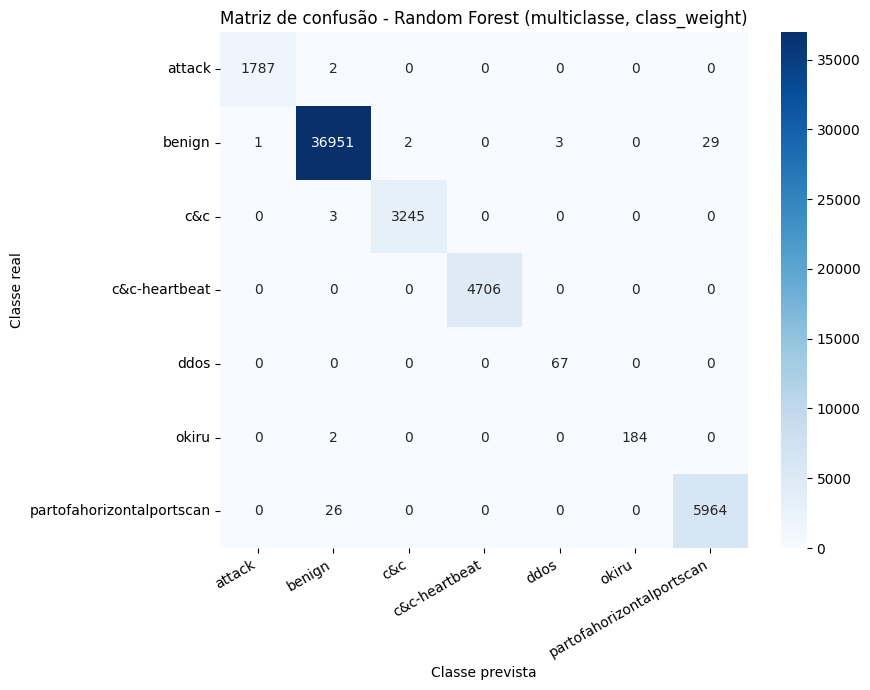

In [ ]:
rf_binario_cw, y_pred_rf_bin_cw, tempo_rf_bin_cw = treinar_avaliar(
    "Random Forest (binário) - class_weight",
    RandomForestClassifier(class_weight="balanced", **RF_KWARGS),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste)

rf_binario_smote, y_pred_rf_bin_smote, tempo_rf_bin_smote = treinar_avaliar(
    "Random Forest (binário) - SMOTE",
    RandomForestClassifier(**RF_KWARGS),        # sem class_weight: SMOTE já balanceou
    X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste)

rf_multi_cw, y_pred_rf_multi_cw, tempo_rf_multi_cw = treinar_avaliar(
    "Random Forest (multiclasse) - class_weight",
    RandomForestClassifier(class_weight="balanced", **RF_KWARGS),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste)

plotar_matriz_confusao(y_multi_teste, y_pred_rf_multi_cw, rf_multi_cw.classes_,
                       "Matriz de confusão - Random Forest (multiclasse, class_weight)",
                       "matriz_confusao_rf_multiclasse.png");

### 4.2 — Árvore de Decisão


=== Árvore de Decisão (binário) - class_weight === (treino: 0.83s)
              precision    recall  f1-score   support

      benign     0.9993    0.9994    0.9994     36986
   malicious     0.9987    0.9984    0.9986     15986

    accuracy                         0.9991     52972
   macro avg     0.9990    0.9989    0.9990     52972
weighted avg     0.9991    0.9991    0.9991     52972


=== Árvore de Decisão (binário) - SMOTE === (treino: 1.67s)
              precision    recall  f1-score   support

      benign     0.9995    0.9986    0.9991     36986
   malicious     0.9969    0.9987    0.9978     15986

    accuracy                         0.9987     52972
   macro avg     0.9982    0.9987    0.9984     52972
weighted avg     0.9987    0.9987    0.9987     52972


=== Árvore de Decisão (multiclasse) - class_weight === (treino: 0.71s)
                           precision    recall  f1-score   support

                   attack     0.9994    1.0000    0.9997      1789
          

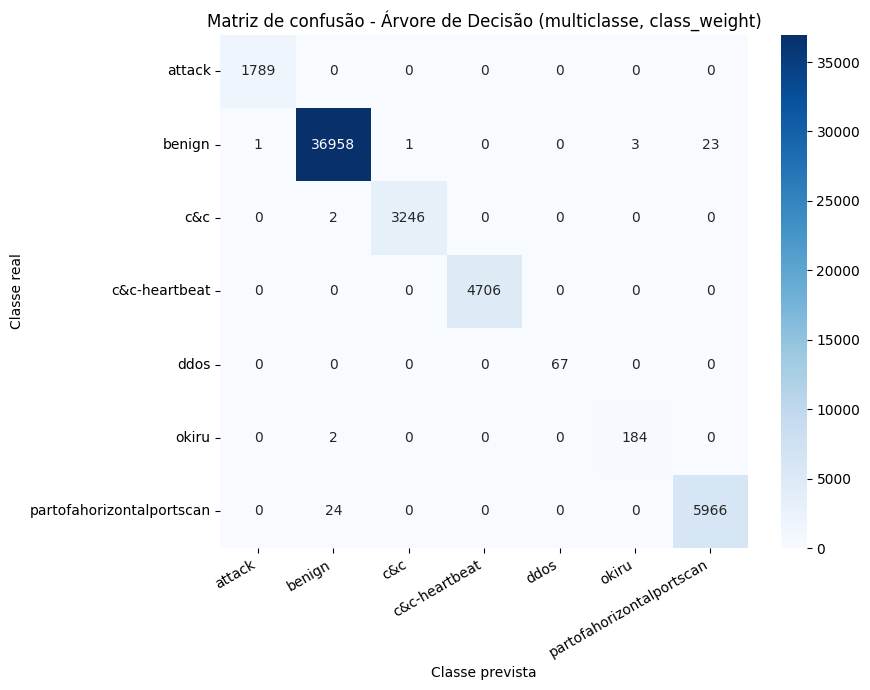

In [ ]:
dt_binario_cw, y_pred_dt_bin_cw, tempo_dt_bin_cw = treinar_avaliar(
    "Árvore de Decisão (binário) - class_weight",
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste)

dt_binario_smote, y_pred_dt_bin_smote, tempo_dt_bin_smote = treinar_avaliar(
    "Árvore de Decisão (binário) - SMOTE",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste)

dt_multi_cw, y_pred_dt_multi_cw, tempo_dt_multi_cw = treinar_avaliar(
    "Árvore de Decisão (multiclasse) - class_weight",
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste)

plotar_matriz_confusao(y_multi_teste, y_pred_dt_multi_cw, dt_multi_cw.classes_,
                       "Matriz de confusão - Árvore de Decisão (multiclasse, class_weight)",
                       "matriz_confusao_dt_multiclasse.png");

### 4.3 — SVM (hiperparâmetros padrão, com cache no Drive)

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_binario_padrao.joblib

=== SVM (binário) - class_weight (padrão) === (treino: 641.53s)
              precision    recall  f1-score   support

      benign     0.9977    0.9038    0.9484     36986
   malicious     0.8172    0.9952    0.8974     15986

    accuracy                         0.9314     52972
   macro avg     0.9074    0.9495    0.9229     52972
weighted avg     0.9432    0.9314    0.9330     52972

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_multi_padrao.joblib

=== SVM (multiclasse) - class_weight (padrão) === (treino: 731.87s)
                           precision    recall  f1-score   support

                   attack     0.9160    1.0000    0.9562      1789
                   benign     0.9975    0.9022    0.9475     36986
                      c&c     0.5857    0.6228    0.6037      3248
            c&c-heartbeat     0.7031    1.0000    0.8257      4706
                     ddos     0

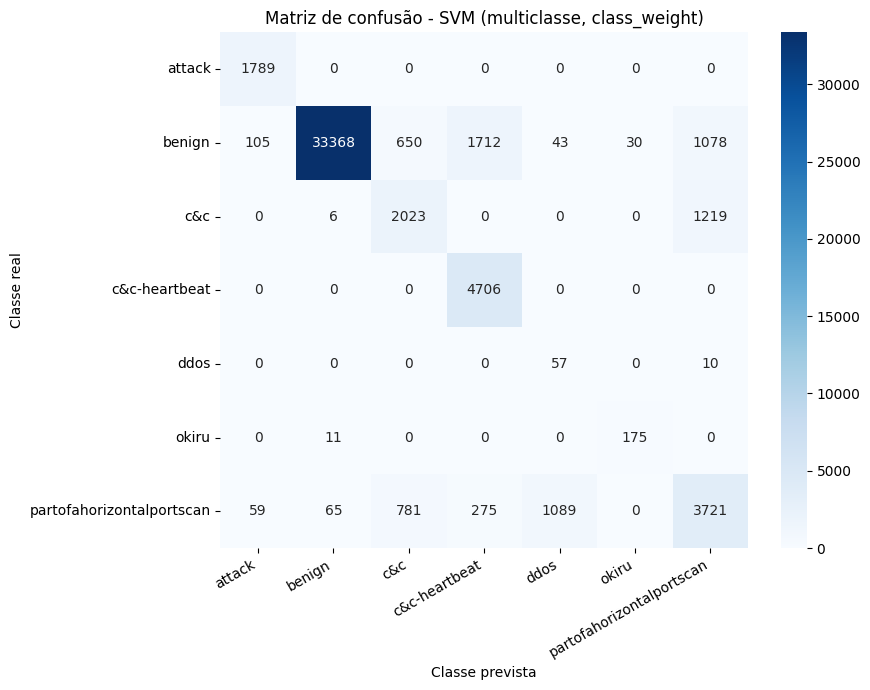

In [ ]:
# SVM+SMOTE binário: executado uma vez; resultado registrado para citar no texto.
RESULTADO_SVM_SMOTE_BINARIO = {
    "tempo_treino_s": 1486.34, "acuracia": 0.93, "f1_macro": 0.93,
    "observacao": "praticamente igual ao class_weight (F1-macro 0.92), com ~2x o tempo de treino",
}

# cache_size em MB: o padrão (200) é pequeno para ~120 mil amostras
svm_binario_padrao, y_pred_svm_bin_padrao, tempo_svm_bin_padrao = treinar_avaliar(
    "SVM (binário) - class_weight (padrão)",
    SVC(kernel="rbf", class_weight="balanced", cache_size=2000),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_padrao", retreinar=RETREINAR_SVM)

svm_multi_padrao, y_pred_svm_multi_padrao, tempo_svm_multi_padrao = treinar_avaliar(
    "SVM (multiclasse) - class_weight (padrão)",
    SVC(kernel="rbf", class_weight="balanced", cache_size=2000),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_padrao", retreinar=RETREINAR_SVM)

plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_padrao, svm_multi_padrao.classes_,
                       "Matriz de confusão - SVM (multiclasse, class_weight)",
                       "matriz_confusao_svm_multiclasse.png");

### 4.4 — CNN (Keras + TensorFlow)

Como previsto na proposta, cada vetor de atributos é reorganizado numa matriz 2D, análoga a uma imagem. Com 42 atributos, a matriz 6×7 fecha exatamente, então nenhum *zero-padding* é necessário. O código ainda preenche com zeros automaticamente se o número de atributos mudar.

- **Arquitetura:** 2 camadas Conv2D (ReLU, `padding='same'`) → MaxPooling 2×2 → Flatten → Dense + Dropout → Softmax.
- **Balanceamento:** `class_weight='balanced'` nas duas tarefas, mesmo critério dos modelos clássicos.
- **Validação:** holdout de 20% retirado do **treino**, estratificado pelo rótulo multiclasse. Ele é usado pelo *early stopping* e pela seleção de hiperparâmetros; o conjunto de teste continua intocado.
- **Primeiro modelo:** a CNN abaixo usa hiperparâmetros "padrão". O ajuste vem na Seção 5.3.

In [ ]:
# 4.4.1 — Funções da CNN

# Holdout de validação dentro do treino (índices posicionais), estratificado pelo multiclasse
idx_cnn_tr, idx_cnn_val = train_test_split(
    np.arange(len(X_treino_norm)), test_size=CNN_VALIDACAO,
    random_state=RANDOM_STATE, stratify=y_multi_treino.astype(str))
print(f"CNN — treino: {len(idx_cnn_tr)} | validação: {len(idx_cnn_val)}")


def formato_para(n_atributos):
    """Matriz o mais quadrada possível: 42 -> 6x7 (sem padding); 50 -> 7x8 (com 6 zeros)."""
    h = int(np.floor(np.sqrt(n_atributos)))
    return h, int(np.ceil(n_atributos / h))

assert formato_para(42) == CNN_FORMATO


def para_matriz(X, formato=None):
    """Vetor de n atributos -> matriz (altura x largura x 1 canal), com zero-padding se necessário."""
    arr = np.asarray(X, dtype=np.float32)
    h, w = formato or formato_para(arr.shape[1])
    faltam = h * w - arr.shape[1]
    if faltam < 0:
        raise ValueError(f"{arr.shape[1]} atributos não cabem numa matriz {h}x{w}")
    if faltam > 0:
        arr = np.pad(arr, ((0, 0), (0, faltam)))
    return arr.reshape(-1, h, w, 1)


def construir_cnn(n_classes, formato=CNN_FORMATO, filtros=(32, 64), kernel=2, densa=128, dropout=0.3, lr=1e-3):
    h, w = formato
    modelo = keras.Sequential([
        keras.layers.Input(shape=(h, w, 1)),
        keras.layers.Conv2D(filtros[0], kernel, padding="same", activation="relu"),
        keras.layers.Conv2D(filtros[1], kernel, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Flatten(),
        keras.layers.Dense(densa, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(n_classes, activation="softmax"),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


class ClassificadorCNN:
    """Dá à CNN a mesma interface dos modelos do scikit-learn (predict -> rótulos, classes_),
    para ela entrar nas mesmas células de inferência, McNemar e testes externos."""
    def __init__(self, modelo, classes):
        self.modelo = modelo
        self.classes_ = np.asarray(classes, dtype=str)
        self.formato = tuple(modelo.input_shape[1:3])     # lido do próprio modelo

    def predict(self, X):
        proba = self.modelo.predict(para_matriz(X, self.formato), batch_size=8192, verbose=0)
        return self.classes_[proba.argmax(axis=1)]


def id_config(params):
    return hashlib.md5(json.dumps(params, sort_keys=True).encode()).hexdigest()[:8]


def ajustar_cnn(X_fit, y_fit, X_val, y_val, classes, params, seed, verbose=0):
    """Núcleo do treino: class_weight balanceado, early stopping na validação.
    y_fit/y_val: arrays de rótulos (str). Retorna (ClassificadorCNN, history, tempo_s)."""
    classes = np.asarray(classes, dtype=str)
    y_fit_cod = np.searchsorted(classes, np.asarray(y_fit, dtype=str))
    y_val_cod = np.searchsorted(classes, np.asarray(y_val, dtype=str))
    presentes = np.unique(y_fit_cod)
    pesos = compute_class_weight("balanced", classes=presentes, y=y_fit_cod)

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)              # numpy, python e TF com a mesma seed
    arq = {k: v for k, v in params.items() if k != "batch"}
    formato = formato_para(X_fit.shape[1])
    modelo = construir_cnn(len(classes), formato, **arq)
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CNN_PACIENCIA,
                                           restore_best_weights=True)
    t0 = time.perf_counter()
    hist = modelo.fit(para_matriz(X_fit, formato), y_fit_cod,
                      validation_data=(para_matriz(X_val, formato), y_val_cod),
                      epochs=CNN_EPOCAS_MAX, batch_size=params["batch"],
                      class_weight=dict(zip(presentes, pesos)), callbacks=[parada], verbose=verbose)
    return ClassificadorCNN(modelo, classes), hist, time.perf_counter() - t0


def treinar_cnn(tarefa, y_treino_completo, params, seed, verbose=0):
    """Treina uma CNN no treino (menos o holdout), com early stopping no holdout.
    Cada combinação (tarefa, configuração, seed) fica em cache em CNN_DIR.
    Retorna (ClassificadorCNN, metadados)."""
    # o nome inclui épocas máx. e paciência: mudar esses valores gera modelos novos (não reaproveita os antigos)
    chave = {**params, "epocas_max": CNN_EPOCAS_MAX, "paciencia": CNN_PACIENCIA}
    nome = f"cnn_{tarefa}_{id_config(chave)}_s{seed}"
    caminho_modelo, caminho_meta = f"{CNN_DIR}/{nome}.keras", f"{CNN_DIR}/{nome}.json"
    if os.path.exists(caminho_modelo) and os.path.exists(caminho_meta) and not RETREINAR_CNN:
        meta = json.load(open(caminho_meta))
        return ClassificadorCNN(keras.models.load_model(caminho_modelo), meta["classes"]), meta

    y_str = np.asarray(y_treino_completo.astype(str))
    classes = np.unique(y_str)
    clf, hist, tempo = ajustar_cnn(X_treino_norm.iloc[idx_cnn_tr], y_str[idx_cnn_tr],
                                   X_treino_norm.iloc[idx_cnn_val], y_str[idx_cnn_val],
                                   classes, params, seed, verbose)
    pred_val = clf.predict(X_treino_norm.iloc[idx_cnn_val])
    meta = {"tarefa": tarefa, "params": params, "seed": seed, "classes": [str(c) for c in classes],
            "tempo_treino_s": tempo, "epocas": len(hist.history["loss"]),
            "f1_macro_val": float(f1_score(y_str[idx_cnn_val], pred_val, average="macro")),
            "historico": {k: [float(x) for x in v] for k, v in hist.history.items()}}
    clf.modelo.save(caminho_modelo)
    json.dump(meta, open(caminho_meta, "w"))
    return clf, meta


def avaliar_cnn(titulo, clf, meta, y_te):
    y_pred = clf.predict(X_teste_norm)
    print(f"\n=== {titulo} === (treino: {meta['tempo_treino_s']:.1f}s, {meta['epocas']} épocas, "
          f"F1-macro na validação: {meta['f1_macro_val']:.4f})")
    print(classification_report(y_te, y_pred, digits=4, zero_division=0))
    return y_pred


def plotar_curvas(meta, titulo, nome_arquivo):
    h = meta["historico"]
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
    for eixo, chave in zip(eixos, ["loss", "accuracy"]):
        eixo.plot(h[chave], label="treino")
        eixo.plot(h[f"val_{chave}"], label="validação")
        eixo.set_title(chave); eixo.set_xlabel("época"); eixo.legend()
    fig.suptitle(titulo); plt.tight_layout(); salvar_figura(nome_arquivo); plt.show()

print("Funções da CNN prontas.")

CNN — treino: 98880 | validação: 24720
Funções da CNN prontas.



=== CNN (binário) - padrão === (treino: 1347.5s, 98 épocas, F1-macro na validação: 0.9751)
              precision    recall  f1-score   support

      benign     0.9983    0.9690    0.9834     36986
   malicious     0.9328    0.9962    0.9635     15986

    accuracy                         0.9772     52972
   macro avg     0.9656    0.9826    0.9735     52972
weighted avg     0.9786    0.9772    0.9774     52972


=== CNN (multiclasse) - padrão === (treino: 592.3s, 44 épocas, F1-macro na validação: 0.6970)
                           precision    recall  f1-score   support

                   attack     0.9418    0.9950    0.9677      1789
                   benign     0.9992    0.9316    0.9642     36986
                      c&c     0.7052    0.9778    0.8194      3248
            c&c-heartbeat     0.9634    1.0000    0.9813      4706
                     ddos     0.0365    0.9104    0.0702        67
                    okiru     0.3054    1.0000    0.4679       186
partofahorizonta

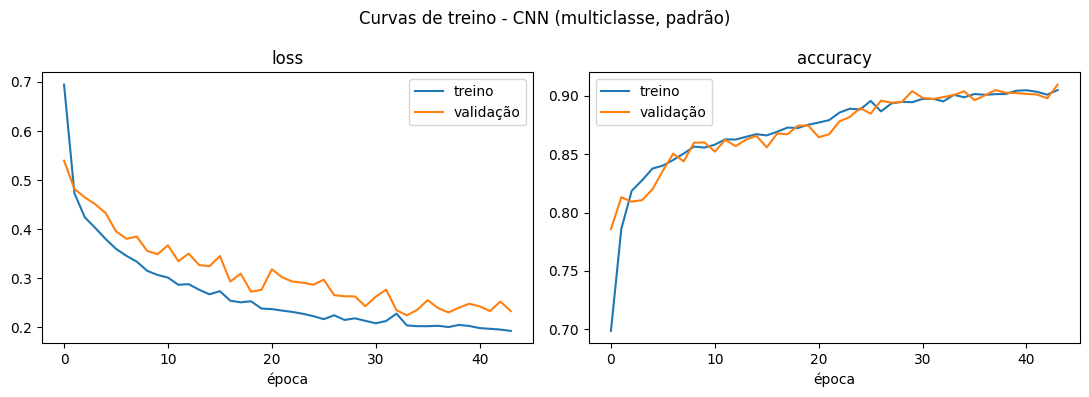

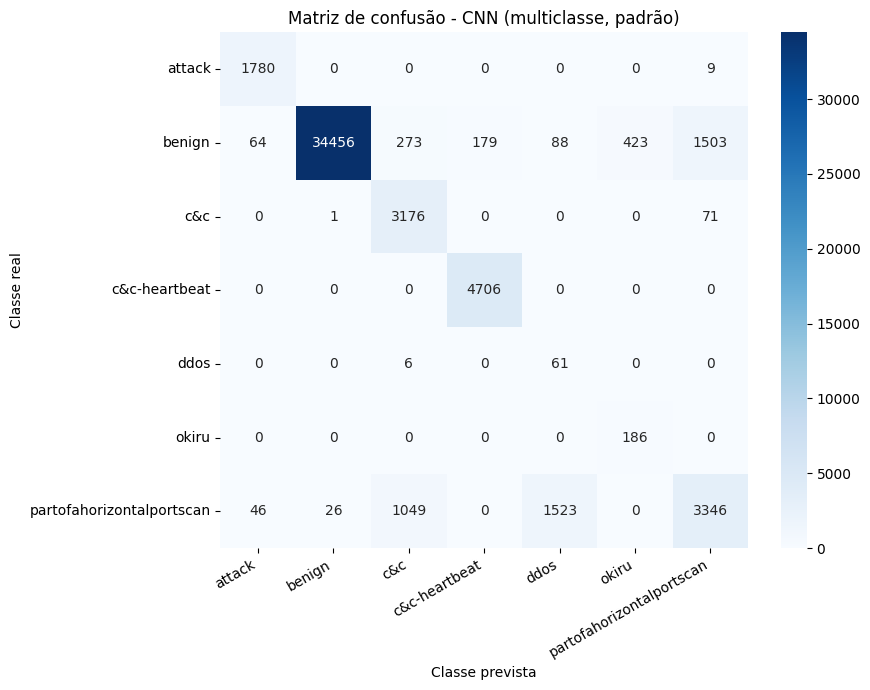

In [ ]:
# 4.4.2 — CNN com hiperparâmetros padrão (seed 42)
CNN_PARAMS_PADRAO = {"filtros": [32, 64], "kernel": 2, "densa": 128, "dropout": 0.3, "lr": 1e-3, "batch": 256}

cnn_binario_padrao, meta_cnn_bin_padrao = treinar_cnn("binario", y_bin_treino, CNN_PARAMS_PADRAO, RANDOM_STATE)
y_pred_cnn_bin_padrao = avaliar_cnn("CNN (binário) - padrão", cnn_binario_padrao, meta_cnn_bin_padrao, y_bin_teste)

cnn_multi_padrao, meta_cnn_multi_padrao = treinar_cnn("multiclasse", y_multi_treino, CNN_PARAMS_PADRAO, RANDOM_STATE)
y_pred_cnn_multi_padrao = avaliar_cnn("CNN (multiclasse) - padrão", cnn_multi_padrao, meta_cnn_multi_padrao, y_multi_teste)

plotar_curvas(meta_cnn_multi_padrao, "Curvas de treino - CNN (multiclasse, padrão)", "curvas_cnn_multiclasse_padrao.png")
plotar_matriz_confusao(y_multi_teste, y_pred_cnn_multi_padrao, cnn_multi_padrao.classes_,
                       "Matriz de confusão - CNN (multiclasse, padrão)",
                       "matriz_confusao_cnn_multiclasse_padrao.png");

## 5. Etapa 4 — Ajuste de hiperparâmetros

### 5.1 — SVM
O SVM leva ~10 min por treino no conjunto completo, então o Grid Search roda numa **subamostra estratificada**
(classes raras inteiras; benign limitado a 8.000 e as demais a 3.000), com CV estratificada de 5 folds.

- **v1:** grade C ∈ {1, 10, 100} × gamma ∈ {g₀/4, g₀, 4g₀} (g₀ = `gamma='scale'`). O melhor ponto caiu na borda da grade.
- **v2:** grade estendida (C ∈ {10, 100, 1000}, gamma ∈ {g₀, 4g₀, 16g₀}) e F1 ponderado para devolver à subamostra a prevalência natural das classes.

In [ ]:
# Subamostra de tuning (a mesma para binário e multiclasse)
idx_tuning = subamostra_estratificada(y_multi_treino, cap_padrao=3000, caps={"benign": 8000})
print(f"Subamostra de tuning: {len(idx_tuning)} linhas de {len(X_treino_norm)}")
print(y_multi_treino.iloc[idx_tuning].astype(str).value_counts())

Subamostra de tuning: 20591 linhas de 123600
detailed-label
benign                       8000
partofahorizontalportscan    3000
c&c-heartbeat                3000
attack                       3000
c&c                          3000
okiru                         435
ddos                          156
Name: count, dtype: int64


In [ ]:
# 5.1.1 — Tuning v1 (GridSearchCV, F1-macro simples)
def tunar_svm(nome_tarefa, y_completo, idx):
    caminho = f"{MODELOS_DIR}/svm_{nome_tarefa}_melhores_params.json"
    if os.path.exists(caminho) and not RETREINAR_SVM:
        params = json.load(open(caminho))
        print(f"[cache] parâmetros carregados: {params}")
        return params

    X_t = X_treino_norm.iloc[idx]
    y_t = y_completo.iloc[idx].astype(str)
    g0 = 1.0 / (X_t.shape[1] * np.asarray(X_t, dtype=float).var())   # = gamma='scale'
    grade = {"C": [1, 10, 100], "gamma": [g0 / 4, g0, g0 * 4]}
    gs = GridSearchCV(SVC(kernel="rbf", class_weight="balanced", cache_size=1000),
                      grade, scoring="f1_macro",
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                      n_jobs=2, refit=False, verbose=1)
    t0 = time.perf_counter()
    gs.fit(X_t, y_t)
    print(f"Grid Search ({nome_tarefa}) levou {time.perf_counter() - t0:.0f}s")

    res = pd.DataFrame(gs.cv_results_)[["param_C", "param_gamma", "mean_test_score",
                                        "std_test_score", "mean_fit_time"]] \
            .sort_values("mean_test_score", ascending=False)
    print(res.to_string(index=False))
    res.to_csv(f"{MODELOS_DIR}/svm_{nome_tarefa}_grid_resultados.csv", index=False)

    melhor = gs.cv_results_["params"][int(np.argmin(gs.cv_results_["rank_test_score"]))]
    params = {"C": float(melhor["C"]), "gamma": float(melhor["gamma"]), "gamma_scale_ref": float(g0)}
    if params["C"] in (1, 100) or params["gamma"] in (g0 / 4, g0 * 4):
        print("ATENÇÃO: o melhor ponto está na borda da grade.")
    json.dump(params, open(caminho, "w"))
    return params

params_svm_bin_v1   = tunar_svm("binario",     y_bin_treino,   idx_tuning)
params_svm_multi_v1 = tunar_svm("multiclasse", y_multi_treino, idx_tuning)

[cache] parâmetros carregados: {'C': 100.0, 'gamma': 0.24474919852435617, 'gamma_scale_ref': 0.06118729963108904}
[cache] parâmetros carregados: {'C': 100.0, 'gamma': 0.24474919852435617, 'gamma_scale_ref': 0.06118729963108904}


In [ ]:
# 5.1.2 — Tuning v2 (grade estendida + F1 ponderado pela prevalência natural)
cont_full = y_multi_treino.astype(str).value_counts()
y_multi_sub = y_multi_treino.iloc[idx_tuning].astype(str)
peso_por_classe = (cont_full / y_multi_sub.value_counts()).to_dict()
w_sub = y_multi_sub.map(peso_por_classe).to_numpy(dtype=float)
print("Peso de cada classe na avaliação:", {k: round(v, 2) for k, v in peso_por_classe.items()})


def tunar_svm_ponderado(nome_tarefa, y_task, Cs, mult_gamma, sufixo="v2"):
    caminho = f"{MODELOS_DIR}/svm_{nome_tarefa}_melhores_params_{sufixo}.json"
    if os.path.exists(caminho) and not RETREINAR_SVM:
        params = json.load(open(caminho))
        print(f"[cache] parâmetros carregados: {params}")
        return params

    X_t = X_treino_norm.iloc[idx_tuning]
    y_t = y_task.iloc[idx_tuning].astype(str)
    g0 = 1.0 / (X_t.shape[1] * np.asarray(X_t, dtype=float).var())
    # folds estratificados pelo rótulo multiclasse (garante ddos/okiru em todos os folds)
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_t, y_multi_sub))
    combos = [(C, m * g0, m) for C in Cs for m in mult_gamma]

    def avaliar(C, gamma, tr, va):
        modelo = SVC(kernel="rbf", class_weight="balanced", cache_size=1000, C=C, gamma=gamma)
        modelo.fit(X_t.iloc[tr], y_t.iloc[tr])
        pred = modelo.predict(X_t.iloc[va])
        _, _, f1, _ = precision_recall_fscore_support(
            y_t.iloc[va], pred, average="macro", sample_weight=w_sub[va], zero_division=0)
        return f1

    t0 = time.perf_counter()
    scores = Parallel(n_jobs=2)(delayed(avaliar)(C, g, tr, va) for (C, g, _) in combos for (tr, va) in folds)
    print(f"Grid ({nome_tarefa}) levou {time.perf_counter() - t0:.0f}s")

    scores = np.array(scores).reshape(len(combos), len(folds))
    res = pd.DataFrame({"C": [c[0] for c in combos], "gamma_mult": [c[2] for c in combos],
                        "gamma": [c[1] for c in combos],
                        "f1_macro_ponderado": scores.mean(axis=1), "desvio": scores.std(axis=1)}
                       ).sort_values("f1_macro_ponderado", ascending=False)
    print(res.to_string(index=False))
    res.to_csv(f"{MODELOS_DIR}/svm_{nome_tarefa}_grid_resultados_{sufixo}.csv", index=False)

    melhor = res.iloc[0]
    if melhor["C"] in (min(Cs), max(Cs)) or melhor["gamma_mult"] in (min(mult_gamma), max(mult_gamma)):
        print("ATENÇÃO: melhor ponto na borda da grade.")
    params = {"C": float(melhor["C"]), "gamma": float(melhor["gamma"]),
              "gamma_mult": float(melhor["gamma_mult"]), "gamma_scale_ref": float(g0)}
    json.dump(params, open(caminho, "w"))
    return params


CS, MULT_GAMMA = [10, 100, 1000], [1, 4, 16]
params_svm_bin_v2   = tunar_svm_ponderado("binario",     y_bin_treino,   CS, MULT_GAMMA)
params_svm_multi_v2 = tunar_svm_ponderado("multiclasse", y_multi_treino, CS, MULT_GAMMA)

Peso de cada classe na avaliação: {'attack': 1.39, 'benign': 10.79, 'c&c': 2.53, 'c&c-heartbeat': 3.66, 'ddos': 1.0, 'okiru': 1.0, 'partofahorizontalportscan': 4.66}
[cache] parâmetros carregados: {'C': 1000.0, 'gamma': 0.9789967940974247, 'gamma_mult': 16.0, 'gamma_scale_ref': 0.06118729963108904}
[cache] parâmetros carregados: {'C': 1000.0, 'gamma': 0.9789967940974247, 'gamma_mult': 16.0, 'gamma_scale_ref': 0.06118729963108904}


[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_binario_tuned.joblib

=== SVM (binário) - tuning v1 === (treino: 470.85s)
              precision    recall  f1-score   support

      benign     0.9984    0.9282    0.9620     36986
   malicious     0.8571    0.9966    0.9216     15986

    accuracy                         0.9488     52972
   macro avg     0.9278    0.9624    0.9418     52972
weighted avg     0.9558    0.9488    0.9498     52972

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_multi_tuned.joblib

=== SVM (multiclasse) - tuning v1 === (treino: 301.39s)
                           precision    recall  f1-score   support

                   attack     0.9485    0.9989    0.9730      1789
                   benign     0.9990    0.9136    0.9544     36986
                      c&c     0.5674    0.9335    0.7058      3248
            c&c-heartbeat     0.9060    1.0000    0.9507      4706
                     ddos     0.0386    0.8806    0.0740 

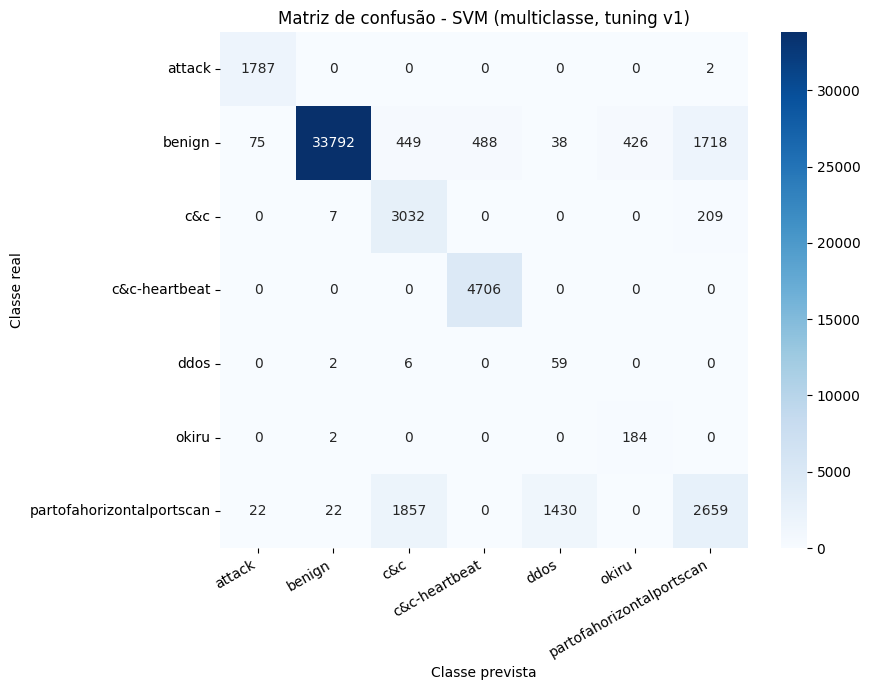

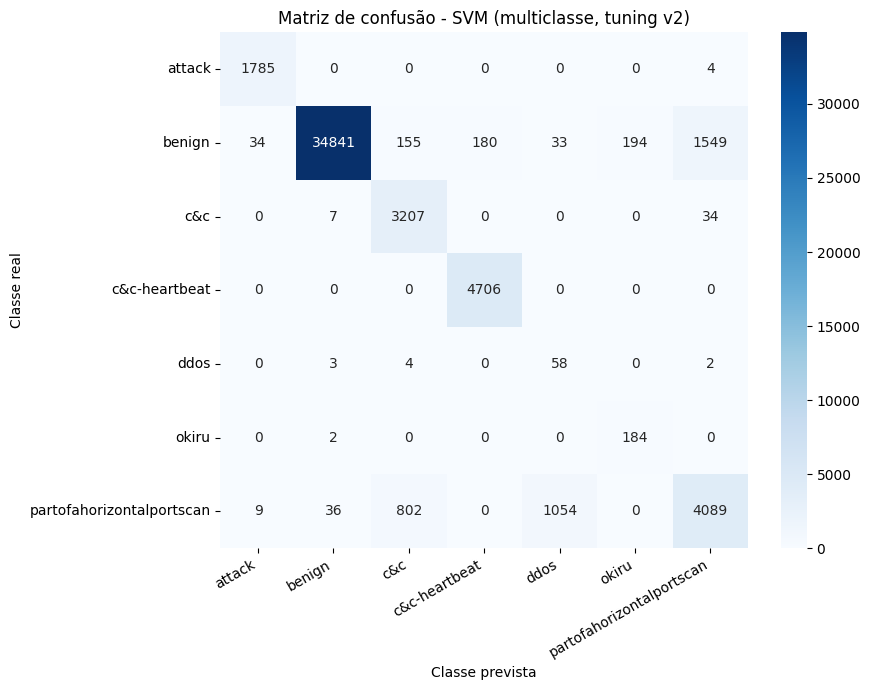

In [ ]:
# 5.1.3 — Fit final no treino COMPLETO com os hiperparâmetros de cada versão (cache no Drive)
def svm_com(params):
    return SVC(kernel="rbf", class_weight="balanced", cache_size=2000, C=params["C"], gamma=params["gamma"])

svm_binario_v1, y_pred_svm_bin_v1, tempo_svm_bin_v1 = treinar_avaliar(
    "SVM (binário) - tuning v1", svm_com(params_svm_bin_v1),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_tuned", retreinar=RETREINAR_SVM)
svm_multi_v1, y_pred_svm_multi_v1, tempo_svm_multi_v1 = treinar_avaliar(
    "SVM (multiclasse) - tuning v1", svm_com(params_svm_multi_v1),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_tuned", retreinar=RETREINAR_SVM)

svm_binario_v2, y_pred_svm_bin_v2, tempo_svm_bin_v2 = treinar_avaliar(
    "SVM (binário) - tuning v2", svm_com(params_svm_bin_v2),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_tuned_v2", retreinar=RETREINAR_SVM)
svm_multi_v2, y_pred_svm_multi_v2, tempo_svm_multi_v2 = treinar_avaliar(
    "SVM (multiclasse) - tuning v2", svm_com(params_svm_multi_v2),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_tuned_v2", retreinar=RETREINAR_SVM)

plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_v1, svm_multi_v1.classes_,
                       "Matriz de confusão - SVM (multiclasse, tuning v1)",
                       "matriz_confusao_svm_multiclasse_tuned.png")
plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_v2, svm_multi_v2.classes_,
                       "Matriz de confusão - SVM (multiclasse, tuning v2)",
                       "matriz_confusao_svm_multiclasse_tuned_v2.png");

### 5.2 — Random Forest e Árvore de Decisão: Grid Search + CV estratificada de 5 folds

Busca exaustiva, como previsto na proposta. As grades incluem a configuração padrão usada na Seção 4, então o modelo ajustado nunca fica pior que o padrão na CV. Os folds são os mesmos de todas as outras CVs do notebook (`StratifiedKFold(5, shuffle=True, random_state=42)`).

- **RF:** `n_estimators` ∈ {50, 100, 200} × `max_depth` ∈ {None, 10, 20}
- **AD:** `criterion` ∈ {gini, entropy} × `max_depth` ∈ {None, 5, 10, 20} × `min_samples_leaf` ∈ {1, 5}

Os melhores hiperparâmetros ficam em cache no Drive. Os modelos finais (`RF_FINAL`, `DT_FINAL`) são retreinados no treino completo, o que leva segundos, e passam a ser os usados em toda a Seção 6.

In [ ]:
# 5.2 — Grid Search do RF e da AD
GRADE_RF = {"n_estimators": [50, 100, 200], "max_depth": [None, 10, 20]}
GRADE_DT = {"criterion": ["gini", "entropy"], "max_depth": [None, 5, 10, 20], "min_samples_leaf": [1, 5]}

def rf_com(params):
    return RandomForestClassifier(**{**RF_KWARGS, "class_weight": "balanced", **params})

def dt_com(params):
    return DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **params)


def grid_search_arvores(nome, estimador, grade, y, n_jobs):
    caminho = f"{MODELOS_DIR}/{nome}_melhores_params.json"
    if os.path.exists(caminho) and not RETREINAR_ARVORES:
        params = json.load(open(caminho))
        print(f"[cache] {nome}: {params}")
        return params

    gs = GridSearchCV(estimador, grade, scoring="f1_macro",
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                      n_jobs=n_jobs, refit=False)
    t0 = time.perf_counter()
    gs.fit(X_treino_norm, y)
    print(f"Grid Search {nome}: {time.perf_counter() - t0:.0f}s")

    res = pd.DataFrame(gs.cv_results_)
    colunas = [f"param_{p}" for p in grade] + ["mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
    res = res[colunas].sort_values("rank_test_score")
    print(res.head(5).to_string(index=False))
    salvar_tabela(res, f"grid_search_{nome}.csv")

    params = gs.best_params_
    # aviso de borda: só n_estimators faz sentido (max_depth tem None = sem limite; min_samples_leaf=1 é o mínimo)
    if "n_estimators" in params and params["n_estimators"] in (min(grade["n_estimators"]), max(grade["n_estimators"])):
        print(f"  ATENÇÃO: n_estimators={params['n_estimators']} está na borda da grade.")
    json.dump(params, open(caminho, "w"))
    print(f"Melhor ({nome}): {params}\n")
    return params


PARAMS_RF = {
    "binário":     grid_search_arvores("rf_binario",     rf_com({}), GRADE_RF, y_bin_treino,   n_jobs=1),
    "multiclasse": grid_search_arvores("rf_multiclasse", rf_com({}), GRADE_RF, y_multi_treino, n_jobs=1),
}   # n_jobs=1 no Grid: o próprio RF já usa todos os núcleos (evita estourar RAM)
PARAMS_DT = {
    "binário":     grid_search_arvores("dt_binario",     dt_com({}), GRADE_DT, y_bin_treino,   n_jobs=-1),
    "multiclasse": grid_search_arvores("dt_multiclasse", dt_com({}), GRADE_DT, y_multi_treino, n_jobs=-1),
}

# Modelos finais: retreino no treino completo com os melhores hiperparâmetros
RF_FINAL, DT_FINAL = {}, {}
for tarefa, y_tr, y_te in [("binário", y_bin_treino, y_bin_teste), ("multiclasse", y_multi_treino, y_multi_teste)]:
    RF_FINAL[tarefa] = treinar_avaliar(f"Random Forest ({tarefa}) - ajustado {PARAMS_RF[tarefa]}",
                                       rf_com(PARAMS_RF[tarefa]), X_treino_norm, y_tr, X_teste_norm, y_te)
    DT_FINAL[tarefa] = treinar_avaliar(f"Árvore de Decisão ({tarefa}) - ajustada {PARAMS_DT[tarefa]}",
                                       dt_com(PARAMS_DT[tarefa]), X_treino_norm, y_tr, X_teste_norm, y_te)

[cache] rf_binario: {'max_depth': None, 'n_estimators': 100}
[cache] rf_multiclasse: {'max_depth': None, 'n_estimators': 200}
[cache] dt_binario: {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1}
[cache] dt_multiclasse: {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1}

=== Random Forest (binário) - ajustado {'max_depth': None, 'n_estimators': 100} === (treino: 7.09s)
              precision    recall  f1-score   support

      benign     0.9991    0.9988    0.9990     36986
   malicious     0.9972    0.9979    0.9976     15986

    accuracy                         0.9985     52972
   macro avg     0.9982    0.9984    0.9983     52972
weighted avg     0.9985    0.9985    0.9985     52972


=== Árvore de Decisão (binário) - ajustada {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1} === (treino: 1.00s)
              precision    recall  f1-score   support

      benign     0.9993    0.9994    0.9994     36986
   malicious     0.9987    0.9984    0.9986

### 5.3 — CNN: Random Search + holdout + early stopping
Conforme a proposta, a busca é mais restrita que a dos modelos clássicos. São sorteadas `CNN_N_CONFIGS` configurações de um espaço pequeno, sendo a primeira sempre a configuração padrão da Seção 4.4. Cada configuração é avaliada pelo **F1-macro no holdout de validação**, sem tocar no teste.

**Ajuste de convergência:** na primeira rodada, com teto de 50 épocas e paciência 5, várias configurações bateram no teto enquanto a *loss* de validação ainda caía (*underfitting*). Algumas seeds também pararam cedo demais por oscilações da validação. Por isso o teto subiu para 150 épocas e a paciência para 10.

In [ ]:
# 5.3.1 — Random Search da CNN (cada configuração fica em cache: pode interromper e retomar)
ESPACO_CNN = {
    "filtros": [[16, 32], [32, 64], [64, 128]],
    "kernel":  [2, 3],
    "densa":   [64, 128, 256],
    "dropout": [0.2, 0.3, 0.5],
    "lr":      [1e-3, 3e-4],
    "batch":   [256, 512],
}
todas = [dict(zip(ESPACO_CNN, valores)) for valores in itertools.product(*ESPACO_CNN.values())]
todas = [c for c in todas if c != CNN_PARAMS_PADRAO]
sorteio = np.random.default_rng(RANDOM_STATE).choice(len(todas), size=CNN_N_CONFIGS - 1, replace=False)
CONFIGS_CNN = [CNN_PARAMS_PADRAO] + [todas[k] for k in sorteio]


def tunar_cnn(tarefa, y_tr):
    linhas = []
    for k, cfg in enumerate(CONFIGS_CNN):
        _, meta = treinar_cnn(tarefa, y_tr, cfg, RANDOM_STATE)
        linhas.append({"config": k, "id": id_config(cfg), **{p: str(v) for p, v in cfg.items()},
                       "f1_macro_val": meta["f1_macro_val"], "epocas": meta["epocas"],
                       "tempo_treino_s": round(meta["tempo_treino_s"], 1)})
        print(f"[{tarefa}] config {k}: F1-val={meta['f1_macro_val']:.4f} "
              f"({meta['epocas']} épocas, {meta['tempo_treino_s']:.0f}s) {cfg}")
    res = pd.DataFrame(linhas).sort_values("f1_macro_val", ascending=False)
    salvar_tabela(res, f"cnn_random_search_{tarefa}.csv")
    melhor = CONFIGS_CNN[int(res.iloc[0]["config"])]
    print(f"\nMelhor configuração ({tarefa}): {melhor}\n")
    return melhor

params_cnn_bin   = tunar_cnn("binario",     y_bin_treino)
params_cnn_multi = tunar_cnn("multiclasse", y_multi_treino)

[binario] config 0: F1-val=0.9751 (98 épocas, 1348s) {'filtros': [32, 64], 'kernel': 2, 'densa': 128, 'dropout': 0.3, 'lr': 0.001, 'batch': 256}
[binario] config 1: F1-val=0.9730 (106 épocas, 7264s) {'filtros': [64, 128], 'kernel': 3, 'densa': 256, 'dropout': 0.5, 'lr': 0.0003, 'batch': 512}
[binario] config 2: F1-val=0.9424 (14 épocas, 978s) {'filtros': [64, 128], 'kernel': 3, 'densa': 64, 'dropout': 0.3, 'lr': 0.001, 'batch': 256}
[binario] config 3: F1-val=0.9622 (86 épocas, 1112s) {'filtros': [32, 64], 'kernel': 2, 'densa': 128, 'dropout': 0.5, 'lr': 0.0003, 'batch': 256}
[binario] config 4: F1-val=0.9623 (56 épocas, 1080s) {'filtros': [32, 64], 'kernel': 3, 'densa': 256, 'dropout': 0.3, 'lr': 0.0003, 'batch': 512}
[binario] config 5: F1-val=0.9513 (45 épocas, 328s) {'filtros': [16, 32], 'kernel': 2, 'densa': 128, 'dropout': 0.3, 'lr': 0.0003, 'batch': 256}
[binario] config 6: F1-val=0.9739 (126 épocas, 156s) {'filtros': [64, 128], 'kernel': 2, 'densa': 128, 'dropout': 0.3, 'lr': 0

## 6. Etapa 5 — Avaliação e comparação

### 6.1 — Validação cruzada estratificada de 5 folds (sobre o treino)
Todos usam `StratifiedKFold(5, shuffle=True, random_state=42)` sobre o mesmo `y` ⇒ **os folds são idênticos entre modelos** (pré-requisito para testes pareados).

In [ ]:
# 6.1.1 — CV de RF e AD (com os hiperparâmetros ajustados na Seção 5.2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"acuracia": "accuracy", "precisao_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

modelos_para_cv = [
    ("Random Forest - binário",         rf_com(PARAMS_RF["binário"]),     y_bin_treino),
    ("Random Forest - multiclasse",     rf_com(PARAMS_RF["multiclasse"]), y_multi_treino),
    ("Árvore de Decisão - binário",     dt_com(PARAMS_DT["binário"]),     y_bin_treino),
    ("Árvore de Decisão - multiclasse", dt_com(PARAMS_DT["multiclasse"]), y_multi_treino),
]

linhas_cv, folds_cv = [], []
for nome, modelo, y in modelos_para_cv:
    t0 = time.perf_counter()
    r = cross_validate(modelo, X_treino_norm, y, cv=cv, scoring=SCORING, n_jobs=-1)
    tempo = time.perf_counter() - t0
    linha = {"modelo": nome, "tempo_total_s": round(tempo, 1)}
    for m in SCORING:
        linha[f"{m}_medio"] = r[f"test_{m}"].mean()
        linha[f"{m}_desvio"] = r[f"test_{m}"].std()
    linhas_cv.append(linha)
    folds_cv.append(pd.DataFrame({"modelo": nome, "fold": range(5), **{m: r[f"test_{m}"] for m in SCORING}}))
    print(f"{nome}: F1-macro = {linha['f1_macro_medio']:.4f} ± {linha['f1_macro_desvio']:.4f} ({tempo:.1f}s)")

df_resultados_cv = pd.DataFrame(linhas_cv)
df_folds_cv_rf_dt = pd.concat(folds_cv, ignore_index=True)
salvar_tabela(df_resultados_cv, "resultados_cv_rf_dt.csv")
salvar_tabela(df_folds_cv_rf_dt, "resultados_cv_rf_dt_folds.csv")

Random Forest - binário: F1-macro = 0.9981 ± 0.0002 (41.4s)
Random Forest - multiclasse: F1-macro = 0.9933 ± 0.0031 (74.3s)
Árvore de Decisão - binário: F1-macro = 0.9989 ± 0.0002 (6.3s)
Árvore de Decisão - multiclasse: F1-macro = 0.9971 ± 0.0017 (4.8s)
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_cv_rf_dt.csv
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_cv_rf_dt_folds.csv


In [ ]:
# 6.1.2 — CV do SVM (checkpoint por fold: se a sessão cair, basta rodar de novo)
def cv_svm_checkpoint(nome_tarefa, X, y, params, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    y_str = y.astype(str)
    linhas = []
    for k, (tr, va) in enumerate(skf.split(X, y_str)):
        caminho = f"{CV_DIR}/svm_{nome_tarefa}_fold{k}.json"
        if os.path.exists(caminho) and not RETREINAR_SVM:
            linhas.append(json.load(open(caminho)))
            continue
        t0 = time.perf_counter()
        m = svm_com(params)
        m.fit(X.iloc[tr], y_str.iloc[tr])
        t_fit = time.perf_counter() - t0
        pred = m.predict(X.iloc[va])
        p, r, f, _ = precision_recall_fscore_support(y_str.iloc[va], pred, average="macro", zero_division=0)
        res = {"fold": k, "acuracia": accuracy_score(y_str.iloc[va], pred),
               "precisao_macro": p, "recall_macro": r, "f1_macro": f, "tempo_treino_s": t_fit}
        json.dump(res, open(caminho, "w"))
        linhas.append(res)
        print(f"fold {k}: F1-macro={f:.4f} acc={res['acuracia']:.4f} ({t_fit:.0f}s)")
        del m; gc.collect()

    df = pd.DataFrame(linhas)
    print(f"=== SVM {nome_tarefa} — média ± desvio (5 folds) ===")
    print(df.drop(columns="fold").agg(["mean", "std"]).T.round(4).to_string(), "\n")
    df.to_csv(f"{CV_DIR}/svm_{nome_tarefa}_cv_folds.csv", index=False)
    return df

df_cv_svm_bin_v1   = cv_svm_checkpoint("binario",        X_treino_norm, y_bin_treino,   params_svm_bin_v1)
df_cv_svm_multi_v1 = cv_svm_checkpoint("multiclasse",    X_treino_norm, y_multi_treino, params_svm_multi_v1)
df_cv_svm_bin_v2   = cv_svm_checkpoint("binario_v2",     X_treino_norm, y_bin_treino,   params_svm_bin_v2)
df_cv_svm_multi_v2 = cv_svm_checkpoint("multiclasse_v2", X_treino_norm, y_multi_treino, params_svm_multi_v2)

=== SVM binario — média ± desvio (5 folds) ===
                    mean     std
acuracia          0.9494  0.0010
precisao_macro    0.9285  0.0013
recall_macro      0.9627  0.0007
f1_macro          0.9424  0.0011
tempo_treino_s  241.4590  7.0866 

=== SVM multiclasse — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.8742   0.0022
precisao_macro    0.6214   0.0026
recall_macro      0.8790   0.0132
f1_macro          0.6612   0.0031
tempo_treino_s  187.7742  11.6182 

=== SVM binario_v2 — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.9613   0.0008
precisao_macro    0.9436   0.0011
recall_macro      0.9714   0.0005
f1_macro          0.9556   0.0009
tempo_treino_s  444.9675  41.0382 

=== SVM multiclasse_v2 — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.9225   0.0027
precisao_macro    0.7098   0.0069
recall_macro      0.9168   0.0133
f1_macro          0.7505   0.0054
tempo_treino_s  

### 6.1.3 — CNN: 5 execuções independentes
No lugar da CV de 5 folds (cara demais para a rede), a configuração escolhida em 5.3 é treinada com **5 seeds diferentes**, mantendo arquitetura e hiperparâmetros fixos. Os resultados no teste são reportados como média ± desvio padrão.

Para o McNemar e para a tabela final é usada a execução de **F1 mediano**. Assim a CNN não é favorecida pela melhor seed nem prejudicada pela pior.

*Obs.:* em GPU, algumas operações do TensorFlow não são 100% determinísticas. Por isso, a mesma seed pode variar um pouco entre sessões; o desvio padrão das 5 execuções captura justamente essa variabilidade.

=== CNN binario — 5 seeds (teste) ===
 seed  acuracia  precisao_macro  recall_macro  f1_macro  epocas  tempo_treino_s
   42    0.9772          0.9656        0.9826    0.9735      98       1347.5275
    7    0.9753          0.9636        0.9801    0.9713      76        132.1623
  123    0.9690          0.9548        0.9752    0.9641      30         54.8221
 2024    0.9772          0.9655        0.9828    0.9735      72        123.5760
31415    0.9734          0.9611        0.9783    0.9691      66        114.5712
                    mean       std
acuracia          0.9744    0.0034
precisao_macro    0.9621    0.0045
recall_macro      0.9798    0.0032
f1_macro          0.9703    0.0039
epocas           68.4000   24.6333
tempo_treino_s  354.5318  555.9308
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/cnn_seeds_binario.csv
Execução de F1 mediano: seed 7

=== CNN multiclasse — 5 seeds (teste) ===
 seed  acuracia  precisao_macro  recall_macro  f1_macro  epocas  tempo_treino_s
   42 

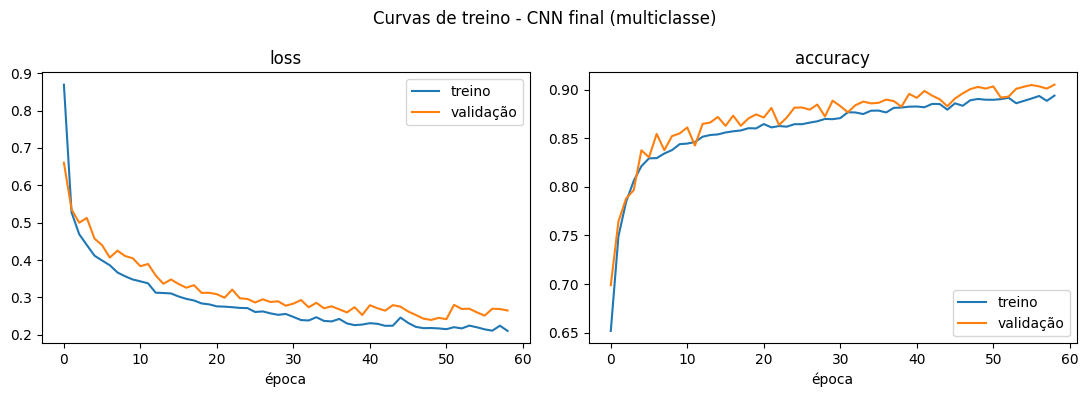

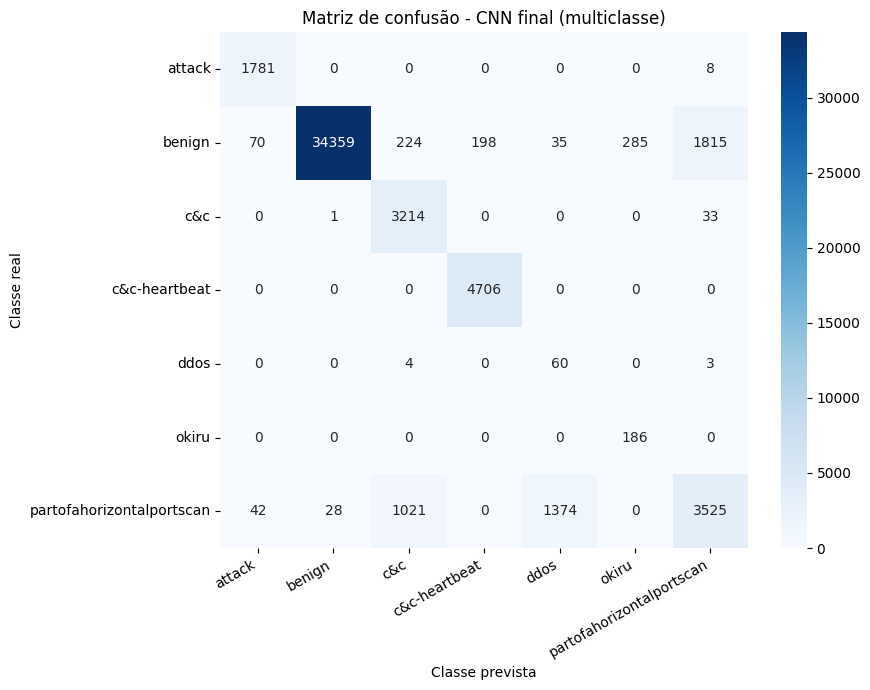

In [ ]:
def cnn_multiplas_seeds(tarefa, y_tr, y_te, params):
    linhas, execucoes = [], {}
    for seed in CNN_SEEDS:
        clf, meta = treinar_cnn(tarefa, y_tr, params, seed)
        y_pred = clf.predict(X_teste_norm)
        p, r, f, _ = precision_recall_fscore_support(y_te, y_pred, average="macro", zero_division=0)
        linhas.append({"seed": seed, "acuracia": accuracy_score(y_te, y_pred), "precisao_macro": p,
                       "recall_macro": r, "f1_macro": f, "epocas": meta["epocas"],
                       "tempo_treino_s": meta["tempo_treino_s"]})
        execucoes[seed] = (clf, y_pred, meta)
    df = pd.DataFrame(linhas)
    print(f"=== CNN {tarefa} — {len(CNN_SEEDS)} seeds (teste) ===")
    print(df.round(4).to_string(index=False))
    print(df.drop(columns="seed").agg(["mean", "std"]).T.round(4).to_string())
    salvar_tabela(df.round(6), f"cnn_seeds_{tarefa}.csv")

    seed_mediana = int(df.sort_values("f1_macro")["seed"].iloc[len(df) // 2])
    print(f"Execução de F1 mediano: seed {seed_mediana}\n")
    clf, y_pred, meta = execucoes[seed_mediana]
    return clf, y_pred, meta, df

cnn_binario_final, y_pred_cnn_bin, meta_cnn_bin, df_seeds_cnn_bin = \
    cnn_multiplas_seeds("binario", y_bin_treino, y_bin_teste, params_cnn_bin)
cnn_multi_final, y_pred_cnn_multi, meta_cnn_multi, df_seeds_cnn_multi = \
    cnn_multiplas_seeds("multiclasse", y_multi_treino, y_multi_teste, params_cnn_multi)

plotar_curvas(meta_cnn_multi, "Curvas de treino - CNN final (multiclasse)", "curvas_cnn_multiclasse_final.png")
plotar_matriz_confusao(y_multi_teste, y_pred_cnn_multi, cnn_multi_final.classes_,
                       "Matriz de confusão - CNN final (multiclasse)",
                       "matriz_confusao_cnn_multiclasse_final.png");

In [ ]:
# 6.2 — Qual SVM reportar? Escolha pelo F1 da CV (treino), NÃO pelo F1 do teste.
def linha_svm(tarefa, variante, y_true, y_pred, df_cv=None):
    return {"tarefa": tarefa, "variante": variante,
            "f1_macro_cv": df_cv["f1_macro"].mean() if df_cv is not None else np.nan,
            "acuracia_teste": accuracy_score(y_true, y_pred),
            "f1_macro_teste": f1_score(y_true, y_pred, average="macro")}

df_comp_svm = pd.DataFrame([
    linha_svm("binário",     "padrão",    y_bin_teste,   y_pred_svm_bin_padrao),
    linha_svm("binário",     "tuning v1", y_bin_teste,   y_pred_svm_bin_v1,   df_cv_svm_bin_v1),
    linha_svm("binário",     "tuning v2", y_bin_teste,   y_pred_svm_bin_v2,   df_cv_svm_bin_v2),
    linha_svm("multiclasse", "padrão",    y_multi_teste, y_pred_svm_multi_padrao),
    linha_svm("multiclasse", "tuning v1", y_multi_teste, y_pred_svm_multi_v1, df_cv_svm_multi_v1),
    linha_svm("multiclasse", "tuning v2", y_multi_teste, y_pred_svm_multi_v2, df_cv_svm_multi_v2),
]).round(4)
print(df_comp_svm.to_string(index=False))
salvar_tabela(df_comp_svm, "comparacao_svm_variantes.csv")

# SVM "oficial" de cada tarefa = maior F1 médio na CV
SVMS = {"tuning v1": {"binário": (svm_binario_v1, y_pred_svm_bin_v1, tempo_svm_bin_v1, df_cv_svm_bin_v1),
                      "multiclasse": (svm_multi_v1, y_pred_svm_multi_v1, tempo_svm_multi_v1, df_cv_svm_multi_v1)},
        "tuning v2": {"binário": (svm_binario_v2, y_pred_svm_bin_v2, tempo_svm_bin_v2, df_cv_svm_bin_v2),
                      "multiclasse": (svm_multi_v2, y_pred_svm_multi_v2, tempo_svm_multi_v2, df_cv_svm_multi_v2)}}
SVM_FINAL = {}
for tarefa in ["binário", "multiclasse"]:
    candidatos = df_comp_svm[(df_comp_svm["tarefa"] == tarefa) & df_comp_svm["f1_macro_cv"].notna()]
    variante = candidatos.sort_values("f1_macro_cv", ascending=False)["variante"].iloc[0]
    SVM_FINAL[tarefa] = (variante, *SVMS[variante][tarefa])
    print(f"SVM escolhido ({tarefa}): {variante}")

     tarefa  variante  f1_macro_cv  acuracia_teste  f1_macro_teste
    binário    padrão          NaN          0.9314          0.9229
    binário tuning v1       0.9424          0.9488          0.9418
    binário tuning v2       0.9556          0.9611          0.9554
multiclasse    padrão          NaN          0.8653          0.7055
multiclasse tuning v1       0.6612          0.8725          0.6604
multiclasse tuning v2       0.7505          0.9226          0.7502
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/comparacao_svm_variantes.csv
SVM escolhido (binário): tuning v2
SVM escolhido (multiclasse): tuning v2


In [ ]:
# 6.3 — Tempo de inferência (ms por amostra, média ± desvio de várias repetições)
# Para o SVM, o custo por amostra não depende do tamanho do lote: mede-se numa subamostra de 5000 linhas.
# CNN: medida em GPU e em CPU. Para comparar com RF/AD/SVM (que rodam em CPU) use a medição em CPU.

class ClassificadorCNNCPU(ClassificadorCNN):
    """Cópia da CNN com pesos idênticos, construída e executada na CPU."""
    def __init__(self, clf):
        with tf.device("/CPU:0"):
            modelo_cpu = keras.models.clone_model(clf.modelo)
            modelo_cpu.set_weights(clf.modelo.get_weights())
        super().__init__(modelo_cpu, clf.classes_)

    def predict(self, X):
        with tf.device("/CPU:0"):
            return super().predict(X)

cnn_binario_cpu, cnn_multi_cpu = ClassificadorCNNCPU(cnn_binario_final), ClassificadorCNNCPU(cnn_multi_final)
assert (cnn_multi_cpu.predict(X_teste_norm.iloc[:500]) == cnn_multi_final.predict(X_teste_norm.iloc[:500])).mean() > 0.99
rng_inf = np.random.default_rng(RANDOM_STATE)
X_inf_svm = X_teste_norm.iloc[rng_inf.choice(len(X_teste_norm), size=min(5000, len(X_teste_norm)), replace=False)]

modelos_para_inferencia = [   # (nome, modelo, X, repetições)
    ("Random Forest - binário (class_weight)",         rf_binario_cw,      X_teste_norm, 10),
    ("Random Forest - binário (SMOTE)",                rf_binario_smote,   X_teste_norm, 10),
    ("Random Forest - multiclasse (class_weight)",     rf_multi_cw,        X_teste_norm, 10),
    ("Árvore de Decisão - binário (class_weight)",     dt_binario_cw,      X_teste_norm, 10),
    ("Árvore de Decisão - binário (SMOTE)",            dt_binario_smote,   X_teste_norm, 10),
    ("Árvore de Decisão - multiclasse (class_weight)", dt_multi_cw,        X_teste_norm, 10),
    ("SVM - binário (padrão)",                         svm_binario_padrao, X_inf_svm, 3),
    ("SVM - multiclasse (padrão)",                     svm_multi_padrao,   X_inf_svm, 3),
    ("SVM - binário (tuning v1)",                      svm_binario_v1,     X_inf_svm, 3),
    ("SVM - multiclasse (tuning v1)",                  svm_multi_v1,       X_inf_svm, 3),
    ("SVM - binário (tuning v2)",                      svm_binario_v2,     X_inf_svm, 3),
    ("SVM - multiclasse (tuning v2)",                  svm_multi_v2,       X_inf_svm, 3),
    ("Random Forest - binário (final)",                RF_FINAL["binário"][0],     X_teste_norm, 10),
    ("Random Forest - multiclasse (final)",            RF_FINAL["multiclasse"][0], X_teste_norm, 10),
    ("Árvore de Decisão - binário (final)",            DT_FINAL["binário"][0],     X_teste_norm, 10),
    ("Árvore de Decisão - multiclasse (final)",        DT_FINAL["multiclasse"][0], X_teste_norm, 10),
    ("CNN - binário (GPU)",                            cnn_binario_final,  X_teste_norm, 5),
    ("CNN - multiclasse (GPU)",                        cnn_multi_final,    X_teste_norm, 5),
    ("CNN - binário (CPU)",                            cnn_binario_cpu,    X_teste_norm, 5),
    ("CNN - multiclasse (CPU)",                        cnn_multi_cpu,      X_teste_norm, 5),
]

resultados_inferencia = []
for nome, modelo, X_inf, n_rep in modelos_para_inferencia:
    modelo.predict(X_inf.iloc[:200])                   # aquecimento
    tempos = []
    for _ in range(n_rep):
        t0 = time.perf_counter()
        modelo.predict(X_inf)
        tempos.append((time.perf_counter() - t0) / len(X_inf) * 1000)
    resultados_inferencia.append({"modelo": nome, "n_amostras_medidas": len(X_inf), "repeticoes": n_rep,
                                  "tempo_medio_ms_amostra": np.mean(tempos),
                                  "tempo_desvio_ms_amostra": np.std(tempos)})
    print(f"{nome}: {np.mean(tempos):.5f} ± {np.std(tempos):.5f} ms/amostra")

df_resultados_inferencia = pd.DataFrame(resultados_inferencia)
salvar_tabela(df_resultados_inferencia, "resultados_inferencia.csv")

Random Forest - binário (class_weight): 0.00560 ± 0.00109 ms/amostra
Random Forest - binário (SMOTE): 0.00769 ± 0.00118 ms/amostra
Random Forest - multiclasse (class_weight): 0.00561 ± 0.00027 ms/amostra
Árvore de Decisão - binário (class_weight): 0.00015 ± 0.00002 ms/amostra
Árvore de Decisão - binário (SMOTE): 0.00016 ± 0.00002 ms/amostra
Árvore de Decisão - multiclasse (class_weight): 0.00016 ± 0.00002 ms/amostra
SVM - binário (padrão): 1.74068 ± 0.10095 ms/amostra
SVM - multiclasse (padrão): 3.68229 ± 0.05541 ms/amostra
SVM - binário (tuning v1): 1.14474 ± 0.14440 ms/amostra
SVM - multiclasse (tuning v1): 2.43221 ± 0.07515 ms/amostra
SVM - binário (tuning v2): 0.79334 ± 0.14209 ms/amostra
SVM - multiclasse (tuning v2): 1.71362 ± 0.11402 ms/amostra
Random Forest - binário (final): 0.00479 ± 0.00021 ms/amostra
Random Forest - multiclasse (final): 0.01079 ± 0.00023 ms/amostra
Árvore de Decisão - binário (final): 0.00014 ± 0.00001 ms/amostra
Árvore de Decisão - multiclasse (final): 0.0

In [ ]:
# 6.4 — Tabela consolidada (modelos finais) — base para o capítulo de resultados
# RF/AD: hiperparâmetros da Seção 5.2 · SVM: variante escolhida pela CV · CNN: seed de F1 mediano
# Inferência: todos medidos em CPU (CNN na GPU está na tabela da Seção 6.3)
# Colunas "f1_rep_*": variabilidade do modelo — CV de 5 folds no treino (RF/AD/SVM)
# ou 5 seeds no teste (CNN), conforme a coluna "repeticao".
inferencia_ms = df_resultados_inferencia.set_index("modelo")["tempo_medio_ms_amostra"]
cv_rf_dt = df_resultados_cv.set_index("modelo")

def linha_final(algoritmo, tarefa, y_true, y_pred, tempo_treino, nome_inferencia, f1_rep, f1_rep_std, repeticao):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"algoritmo": algoritmo, "tarefa": tarefa,
            "acuracia": accuracy_score(y_true, y_pred), "precisao_macro": p, "recall_macro": r,
            "f1_macro": f, "f1_rep_media": f1_rep, "f1_rep_desvio": f1_rep_std, "repeticao": repeticao,
            "tempo_treino_s": tempo_treino, "inferencia_ms_amostra": inferencia_ms[nome_inferencia]}

linhas = []
for tarefa, y_te, cnn_pred, meta_cnn, df_seeds in [
        ("binário", y_bin_teste, y_pred_cnn_bin, meta_cnn_bin, df_seeds_cnn_bin),
        ("multiclasse", y_multi_teste, y_pred_cnn_multi, meta_cnn_multi, df_seeds_cnn_multi)]:
    _, rf_pred, rf_t = RF_FINAL[tarefa]
    _, dt_pred, dt_t = DT_FINAL[tarefa]
    cv_rf = cv_rf_dt.loc[f"Random Forest - {tarefa}"]
    cv_dt = cv_rf_dt.loc[f"Árvore de Decisão - {tarefa}"]
    linhas.append(linha_final("Random Forest", tarefa, y_te, rf_pred, rf_t, f"Random Forest - {tarefa} (final)",
                              cv_rf["f1_macro_medio"], cv_rf["f1_macro_desvio"], "CV 5 folds (treino)"))
    linhas.append(linha_final("Árvore de Decisão", tarefa, y_te, dt_pred, dt_t, f"Árvore de Decisão - {tarefa} (final)",
                              cv_dt["f1_macro_medio"], cv_dt["f1_macro_desvio"], "CV 5 folds (treino)"))
    variante, _, svm_pred, svm_t, df_cv_svm = SVM_FINAL[tarefa]
    linhas.append(linha_final(f"SVM ({variante})", tarefa, y_te, svm_pred, svm_t, f"SVM - {tarefa} ({variante})",
                              df_cv_svm["f1_macro"].mean(), df_cv_svm["f1_macro"].std(ddof=0), "CV 5 folds (treino)"))
    linhas.append(linha_final("CNN", tarefa, y_te, cnn_pred, meta_cnn["tempo_treino_s"], f"CNN - {tarefa} (CPU)",
                              df_seeds["f1_macro"].mean(), df_seeds["f1_macro"].std(ddof=0), "5 seeds (teste)"))

df_tabela_final = pd.DataFrame(linhas).round(4)
print(df_tabela_final.to_string(index=False))
salvar_tabela(df_tabela_final, "tabela_resultados_finais.csv")

        algoritmo      tarefa  acuracia  precisao_macro  recall_macro  f1_macro  f1_rep_media  f1_rep_desvio           repeticao  tempo_treino_s  inferencia_ms_amostra
    Random Forest     binário    0.9985          0.9982        0.9984    0.9983        0.9981         0.0002 CV 5 folds (treino)          7.0858                 0.0048
Árvore de Decisão     binário    0.9991          0.9990        0.9989    0.9990        0.9989         0.0002 CV 5 folds (treino)          1.0019                 0.0001
  SVM (tuning v2)     binário    0.9611          0.9434        0.9712    0.9554        0.9556         0.0008 CV 5 folds (treino)        784.6657                 0.7933
              CNN     binário    0.9753          0.9636        0.9801    0.9713        0.9703         0.0035     5 seeds (teste)        132.1623                 0.0400
    Random Forest multiclasse    0.9986          0.9928        0.9974    0.9950        0.9933         0.0031 CV 5 folds (treino)         19.7283                

In [ ]:
# 6.5 — Teste de McNemar (TESTE ESTATÍSTICO PRINCIPAL): comparação par a par no conjunto de teste
# Decisão aprovada com o orientador (ver 6.6). α = 0,05, versão binomial exata.
def tabela_mcnemar(y_true, pred_a, pred_b):
    acerto_a = np.asarray(pred_a) == np.asarray(y_true, dtype=str)
    acerto_b = np.asarray(pred_b) == np.asarray(y_true, dtype=str)
    return [[int(np.sum(acerto_a & acerto_b)),  int(np.sum(acerto_a & ~acerto_b))],
            [int(np.sum(~acerto_a & acerto_b)), int(np.sum(~acerto_a & ~acerto_b))]]

resultados_mcnemar = []
for tarefa, y_te, preds in [
        ("binário", y_bin_teste, {"Random Forest": RF_FINAL["binário"][1], "Árvore de Decisão": DT_FINAL["binário"][1],
                                  "SVM": SVM_FINAL["binário"][2], "CNN": y_pred_cnn_bin}),
        ("multiclasse", y_multi_teste, {"Random Forest": RF_FINAL["multiclasse"][1], "Árvore de Decisão": DT_FINAL["multiclasse"][1],
                                        "SVM": SVM_FINAL["multiclasse"][2], "CNN": y_pred_cnn_multi})]:
    n = len(y_te)
    for a, b in itertools.combinations(preds, 2):
        tabela = tabela_mcnemar(y_te, preds[a], preds[b])
        resultado = mcnemar(tabela, exact=True)
        so_a, so_b = tabela[0][1], tabela[1][0]
        resultados_mcnemar.append({
            "tarefa": tarefa, "comparacao": f"{a} vs {b}",
            "so_a_acerta": so_a, "so_b_acerta": so_b,
            # relevância prática: diferença de acurácia entre os dois, em pontos percentuais
            "diferenca_acuracia_pp": round((so_a - so_b) / n * 100, 3),
            "p_valor": resultado.pvalue,
            "significativo_5%": "SIM" if resultado.pvalue < 0.05 else "não"})

df_mcnemar = pd.DataFrame(resultados_mcnemar)
print(df_mcnemar.to_string(index=False))
salvar_tabela(df_mcnemar, "resultados_mcnemar.csv")

     tarefa                         comparacao  so_a_acerta  so_b_acerta  diferenca_acuracia_pp       p_valor significativo_5%
    binário Random Forest vs Árvore de Decisão           13           44                 -0.059  4.710438e-05              SIM
    binário               Random Forest vs SVM         1996           14                  3.742  0.000000e+00              SIM
    binário               Random Forest vs CNN         1240           10                  2.322  0.000000e+00              SIM
    binário           Árvore de Decisão vs SVM         2024           11                  3.800  0.000000e+00              SIM
    binário           Árvore de Decisão vs CNN         1274           13                  2.381  0.000000e+00              SIM
    binário                         SVM vs CNN          129          881                 -1.420 3.013263e-138              SIM
multiclasse Random Forest vs Árvore de Decisão           28           44                 -0.030  7.636915e-02  

### 6.6 — Decisão sobre o teste estatístico ✅

A proposta previa o teste de Wilcoxon sobre os 5 folds. Com apenas 5 pares, porém, o menor p-valor bilateral possível é 2/2⁵ = 0,0625, e o teste **nunca** atingiria significância a α = 0,05.

Com aprovação do orientador, adotou-se o **teste de McNemar** (Seção 6.5) como teste principal. A escolha segue a recomendação de Dietterich (1998) para algoritmos de alto custo de treinamento, como SVM e CNN neste trabalho. A CV de 5 folds (e as 5 seeds da CNN) passa a ter papel **descritivo**, reportada como média ± desvio padrão.

**Na interpretação:** com ~53 mil amostras de teste, o McNemar detecta diferenças muito pequenas. Por isso a tabela da Seção 6.5 traz também `diferenca_acuracia_pp`. No texto, diferencie *significância estatística* de *relevância prática*.

> Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923.

### 6.7 — Importância de atributos e a hipótese das portas

SVM e CNN confundem muito **portscan ↔ ddos** (e benigno → portscan), enquanto RF e AD separam essas classes quase perfeitamente. A hipótese é que a separação depende de **valores específicos de porta** (`id.resp_p`, `id.orig_p`), que são categóricos por natureza:
- uma árvore isola uma porta exata com um único corte;
- SVM (RBF) e CNN tratam a porta padronizada como grandeza contínua, e "borram" essa fronteira.

Esta seção verifica a hipótese de duas formas: (1) a importância dos atributos no RF final; (2) as portas de destino mais frequentes em cada uma das classes confundidas.

**Resultado (1ª execução):** `id.resp_p` responde por ~37% da importância do RF, e as duas portas somadas por ~45%. Ddos usa a porta 80 em 99,4% dos fluxos; portscan usa as portas 23, 22, 8080, 81 e 2323. Depois da padronização, 80, 81, 22 e 23 viram valores quase idênticos para o SVM e para a CNN.

✅ **Experimento realizado na Seção 8** — codificação categórica das portas: usar one-hot das portas frequentes + "outras" em vez de valor contínuo, e retreinar SVM e CNN. Isso responde ao objetivo específico sobre *"adaptações metodológicas"*.

[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/importancia_atributos_rf_multiclasse.csv


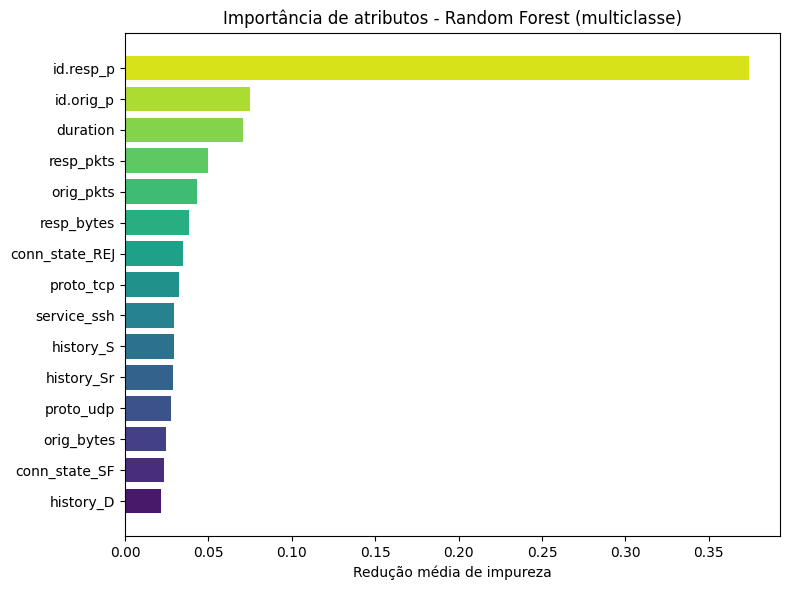

Participação das portas na importância total: 44.9%


In [ ]:
# 6.7.1 — Importância de atributos (redução média de impureza) no RF final multiclasse
importancia = pd.Series(RF_FINAL["multiclasse"][0].feature_importances_,
                        index=X_treino_norm.columns).sort_values(ascending=False)
salvar_tabela(importancia.rename("importancia").rename_axis("atributo").reset_index(),
              "importancia_atributos_rf_multiclasse.csv")

top = importancia.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=sns.color_palette("viridis", len(top)))
plt.title("Importância de atributos - Random Forest (multiclasse)")
plt.xlabel("Redução média de impureza")
plt.tight_layout(); salvar_figura("importancia_atributos_rf_multiclasse.png"); plt.show()

print("Participação das portas na importância total:",
      f"{importancia[['id.resp_p', 'id.orig_p']].sum():.1%}")

In [ ]:
# 6.7.2 — Portas de destino mais frequentes nas classes confundidas (dados de treino, sem normalização)
classe_tr = y_multi_treino.astype(str)
for classe in ["partofahorizontalportscan", "ddos", "benign"]:
    portas = X_treino.loc[classe_tr == classe, "id.resp_p"].value_counts(normalize=True).head(5) * 100
    print(f"\n{classe} — top 5 portas de destino (% dos fluxos da classe):")
    print(portas.round(1).to_string())


partofahorizontalportscan — top 5 portas de destino (% dos fluxos da classe):
id.resp_p
23      36.6
22      16.7
8080    14.1
81      13.3
2323     9.7

ddos — top 5 portas de destino (% dos fluxos da classe):
id.resp_p
80      99.4
5376     0.6

benign — top 5 portas de destino (% dos fluxos da classe):
id.resp_p
81     2.9
123    2.8
53     2.1
22     2.1
1      1.0


## 7. Experimentos complementares — validade dos resultados (Seção 4.4)

Não estavam na proposta, mas sustentam a discussão de limitações:
- **7.1 Ablação da deduplicação:** quanto vazamento treino/teste existiria sem dedup e se isso muda o F1.
- **7.2 Composição por cenário.**
- **7.3 Leave-one-scenario-out (LOSO):** generalização para um cenário de ataque nunca visto.
- **7.4 Teste com distribuição natural** das classes (sem teto de amostragem).

In [ ]:
# 7.1 — Ablação da deduplicação (Random Forest binário)
RF_CW_KWARGS = dict(class_weight="balanced", **RF_KWARGS)

def f1_rf_binario(X_tr, y_tr, X_te, y_te, titulo):
    X_tr_n, X_te_n, _ = normalizar(X_tr, X_te)
    y_pred = RandomForestClassifier(**RF_CW_KWARGS).fit(X_tr_n, y_tr).predict(X_te_n)
    print(f"\n=== {titulo} ===")
    print(classification_report(y_te, y_pred, digits=4))
    return f1_score(y_te, y_pred, average="macro")

# (a) Sem a 2ª deduplicação (X já codificado, antes do drop_duplicates da Seção 3.1)
X_a_tr, X_a_te, y_a_tr, y_a_te = train_test_split(
    X, y_binario, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_binario)
n_ov_a, pct_ov_a = sobreposicao(X_a_tr, X_a_te)
f1_a = f1_rf_binario(X_a_tr, y_a_tr, X_a_te, y_a_te, "RF binário - sem a 2ª dedup")

# (b) Sem NENHUMA deduplicação: amostragem direta do bruto (réplica provável do baseline)
if not os.path.exists(CAMINHO_BRUTO):
    raise FileNotFoundError(f"{CAMINHO_BRUTO} não existe — rode a Seção 2 com REPROCESSAR_DADOS_BRUTOS=True.")
dataset_bruto = ds.dataset(CAMINHO_BRUTO, format="parquet")
CONTAGENS_BRUTO = contar_classes_bruto()          # contagem real, lida do arquivo
print("Linhas por classe no bruto:", CONTAGENS_BRUTO)

rng = np.random.default_rng(RANDOM_STATE)
partes = []
for classe, total in CONTAGENS_BRUTO.items():
    p_manter = min(1.0, CAP_POR_CLASSE * 1.3 / total)   # margem de 30%, depois corta no valor exato
    df_classe = amostrar_classe_bruto(dataset_bruto, classe, p_manter, rng)
    if len(df_classe) > CAP_POR_CLASSE:
        df_classe = df_classe.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)
    print(f"{classe}: {total:,} brutas -> {len(df_classe):,} amostradas")
    partes.append(df_classe)
    gc.collect()
df_sem_dedup = pd.concat(partes, ignore_index=True)
del partes; gc.collect()

X_b, y_b_bin, _ = separar_X_y(preprocessar_features(df_sem_dedup)[0])
X_b_tr, X_b_te, y_b_tr, y_b_te = train_test_split(
    X_b, y_b_bin, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_b_bin)
n_ov_b, pct_ov_b = sobreposicao(X_b_tr, X_b_te)
f1_b = f1_rf_binario(X_b_tr, y_b_tr, X_b_te, y_b_te, "RF binário - sem nenhuma dedup")
del df_sem_dedup, X_b; gc.collect()

# (c) Pipeline atual (dedup completo) = modelo da Seção 4.1
f1_c = f1_score(y_bin_teste, y_pred_rf_bin_cw, average="macro")

resumo_ablacao = pd.DataFrame([
    {"experimento": "(a) Sem a 2ª dedup (X codificado)",                "overlap_treino_teste_%": pct_ov_a, "f1_macro": f1_a},
    {"experimento": "(b) Sem nenhuma dedup (réplica do baseline)",      "overlap_treino_teste_%": pct_ov_b, "f1_macro": f1_b},
    {"experimento": "(c) Pipeline atual (dedup por classe + dedup em X)", "overlap_treino_teste_%": pct_overlap, "f1_macro": f1_c},
]).round(4)
print(resumo_ablacao.to_string(index=False))
salvar_tabela(resumo_ablacao, "resumo_ablacao_dedup.csv")


=== RF binário - sem a 2ª dedup ===
              precision    recall  f1-score   support

      benign     0.9991    0.9989    0.9990     37062
   malicious     0.9974    0.9979    0.9977     15996

    accuracy                         0.9986     53058
   macro avg     0.9982    0.9984    0.9983     53058
weighted avg     0.9986    0.9986    0.9986     53058

Linhas por classe no bruto: {'okiru': 13626744, 'partofahorizontalportscan': 7040929, 'benign': 505082, 'c&c-heartbeat': 15688, 'c&c': 14944, 'ddos': 14394, 'attack': 5962}
okiru: 13,626,744 brutas -> 20,000 amostradas
partofahorizontalportscan: 7,040,929 brutas -> 20,000 amostradas
benign: 505,082 brutas -> 20,000 amostradas
c&c-heartbeat: 15,688 brutas -> 15,688 amostradas
c&c: 14,944 brutas -> 14,944 amostradas
ddos: 14,394 brutas -> 14,394 amostradas
attack: 5,962 brutas -> 5,962 amostradas

=== RF binário - sem nenhuma dedup ===
              precision    recall  f1-score   support

      benign     0.9990    0.9947    0.99

In [ ]:
# 7.2 — Composição de cada cenário (% por classe, após dedup)
composicao_por_cenario = pd.crosstab(origem_cenario_dedup, y_multiclasse_dedup, normalize="index") * 100
print(origem_cenario_dedup.value_counts(), "\n")
print(composicao_por_cenario.round(1))
salvar_tabela(composicao_por_cenario.round(2).reset_index(), "composicao_por_cenario.csv")

origem_cenario
capture_1_1     107872
capture_9_1      23821
capture_36_1     17347
capture_3_1      13740
capture_34_1      7711
capture_8_1       4309
capture_5_1       1195
capture_4_1        452
capture_7_1        125
Name: count, dtype: int64 

detailed-label  attack  benign   c&c  c&c-heartbeat  ddos  okiru  \
origem_cenario                                                     
capture_1_1        0.0    90.3   0.0            0.0   0.0    0.0   
capture_34_1       0.0    10.1  87.0            0.0   2.9    0.0   
capture_36_1       0.0     6.0   0.0           90.4   0.0    3.6   
capture_3_1       43.4    25.6   0.1            0.0   0.0    0.0   
capture_4_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_5_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_7_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_8_1        0.0     4.6  95.4            0.0   0.0    0.0   
capture_9_1        0.0    78.1   0.0            0.0   0.0    0.0   

d

### 7.3 — Leave-one-scenario-out (LOSO) com os 4 modelos finais

Em cada rodada, um cenário de ataque fica **inteiro fora do treino** e vira o teste, junto com 30% dos fluxos dos honeypots benignos (sempre a mesma divisão). Os modelos usam os mesmos hiperparâmetros dos modelos finais da Seção 6:
- RF e AD: ajustados na Seção 5.2;
- SVM: variante escolhida em 6.2;
- CNN: configuração de 5.3 com a seed de F1 mediano. A validação do *early stopping* sai do próprio treino da rodada.

O SVM entra só no binário por padrão (flag `LOSO_SVM_MULTICLASSE`), por custo. Cada predição fica em cache em `resultados/loso/`; se a sessão cair, basta rodar de novo.

**Métricas do binário**, além de acurácia e F1-macro:
- `deteccao_ataque_%`: dos fluxos **maliciosos do cenário nunca visto**, quantos foram detectados;
- `fp_benigno_cenario_%`: falsos alarmes nos benignos **do próprio cenário retirado** (outros dispositivos e redes);
- `fp_benigno_honeypot_%`: falsos alarmes nos benignos de honeypot, cujo padrão foi visto no treino.

In [ ]:
# 7.3.1 — LOSO: cenários e funções
rotulo_bin_str = y_binario_dedup.astype(str)
cenarios_maliciosos = sorted(origem_cenario_dedup[rotulo_bin_str == "malicious"].unique())
cenarios_benignos   = sorted(set(origem_cenario_dedup.unique()) - set(cenarios_maliciosos))
print("Maliciosos:", cenarios_maliciosos, "| Só benignos:", cenarios_benignos)

idx_benigno = origem_cenario_dedup.index[origem_cenario_dedup.isin(cenarios_benignos)]
idx_ben_tr, idx_ben_te = train_test_split(idx_benigno, test_size=TEST_SIZE, random_state=RANDOM_STATE)

SLUG_MODELO = {"Random Forest": "rf", "Árvore de Decisão": "dt", "SVM": "svm", "CNN": "cnn"}
SLUG_TAREFA = {"binário": "binario", "multiclasse": "multiclasse"}


def loso_predicoes(nome, treinar_e_prever):
    """Cache das predições de uma rodada (np.save) + tempo de treino (json)."""
    caminho_pred, caminho_meta = f"{LOSO_DIR}/{nome}.npy", f"{LOSO_DIR}/{nome}.json"
    if os.path.exists(caminho_pred) and os.path.exists(caminho_meta) and not RETREINAR_LOSO:
        return np.load(caminho_pred), json.load(open(caminho_meta))["tempo_s"], True
    t0 = time.perf_counter()
    pred = np.asarray(treinar_e_prever(), dtype=str)
    tempo = time.perf_counter() - t0
    np.save(caminho_pred, pred)
    json.dump({"tempo_s": tempo}, open(caminho_meta, "w"))
    return pred, tempo, False


def modelos_sklearn_loso(tarefa):
    modelos = {"Random Forest": RF_FINAL[tarefa][0], "Árvore de Decisão": DT_FINAL[tarefa][0]}
    if tarefa == "binário" or LOSO_SVM_MULTICLASSE:
        modelos["SVM"] = SVM_FINAL[tarefa][1]
    return modelos


def config_cnn(tarefa):
    if tarefa == "binário":
        return params_cnn_bin, meta_cnn_bin["seed"]
    return params_cnn_multi, meta_cnn_multi["seed"]


def cnn_loso(X_tr_n, y_tr, X_te_n, y_estratificacao, tarefa):
    params, seed = config_cnn(tarefa)
    posicoes = np.arange(len(X_tr_n))
    try:   # validação estratificada pelo multiclasse; se alguma classe tiver 1 exemplo, cai para o rótulo da tarefa
        fit_i, val_i = train_test_split(posicoes, test_size=CNN_VALIDACAO, random_state=RANDOM_STATE,
                                        stratify=y_estratificacao)
    except ValueError:
        fit_i, val_i = train_test_split(posicoes, test_size=CNN_VALIDACAO, random_state=RANDOM_STATE, stratify=y_tr)
    clf, _, _ = ajustar_cnn(X_tr_n.iloc[fit_i], y_tr[fit_i], X_tr_n.iloc[val_i], y_tr[val_i],
                            np.unique(y_tr), params, seed)
    return clf.predict(X_te_n)


def pct(mascara_base, mascara_evento):
    return float(mascara_evento[mascara_base].mean() * 100) if mascara_base.any() else np.nan

Maliciosos: ['capture_1_1', 'capture_34_1', 'capture_36_1', 'capture_3_1', 'capture_8_1', 'capture_9_1'] | Só benignos: ['capture_4_1', 'capture_5_1', 'capture_7_1']


In [ ]:
# 7.3.2 — LOSO: execução (SVM binário é a parte demorada: ~10-15 min por cenário, com cache)
linhas_loso = []
for cenario in cenarios_maliciosos:
    idx_tr = origem_cenario_dedup.index[origem_cenario_dedup.isin([c for c in cenarios_maliciosos if c != cenario])]
    idx_te = origem_cenario_dedup.index[origem_cenario_dedup == cenario]
    idx_tr, idx_te = idx_tr.append(idx_ben_tr), idx_te.append(idx_ben_te)

    X_tr_n, X_te_n, _ = normalizar(X_dedup.loc[idx_tr], X_dedup.loc[idx_te])
    y_multi_tr_l = y_multiclasse_dedup.loc[idx_tr].astype(str).to_numpy()
    do_cenario = (origem_cenario_dedup.loc[idx_te] == cenario).to_numpy()
    nunca_vistas = sorted(set(y_multiclasse_dedup.loc[idx_te].astype(str)) - set(y_multi_tr_l))
    print(f"\n######## {cenario} fora do treino | teste: {len(idx_te)} | "
          f"classes nunca vistas no treino: {nunca_vistas or '—'}")

    for tarefa, y in [("binário", y_binario_dedup), ("multiclasse", y_multiclasse_dedup)]:
        y_tr = y.loc[idx_tr].astype(str).to_numpy()
        y_te = y.loc[idx_te].astype(str).to_numpy()

        rodadas = {}
        for nome_modelo, modelo in modelos_sklearn_loso(tarefa).items():
            chave = id_config({k: str(v) for k, v in modelo.get_params().items()})
            rodadas[nome_modelo] = (chave, lambda m=modelo: clone(m).fit(X_tr_n, y_tr).predict(X_te_n))
        params, seed = config_cnn(tarefa)
        chave_cnn = id_config({**params, "seed": seed, "epocas_max": CNN_EPOCAS_MAX, "paciencia": CNN_PACIENCIA})
        rodadas["CNN"] = (chave_cnn, lambda: cnn_loso(X_tr_n, y_tr, X_te_n, y_multi_tr_l, tarefa))

        for nome_modelo, (chave, treinar_e_prever) in rodadas.items():
            nome_cache = f"{SLUG_TAREFA[tarefa]}_{SLUG_MODELO[nome_modelo]}_{cenario}_{chave}"
            pred, tempo, do_cache = loso_predicoes(nome_cache, treinar_e_prever)
            linha = {"cenario_holdout": cenario, "tarefa": tarefa, "modelo": nome_modelo,
                     "n_teste": len(y_te), "classes_nunca_vistas": ", ".join(nunca_vistas),
                     "acuracia": accuracy_score(y_te, pred),
                     "f1_macro": f1_score(y_te, pred, average="macro", zero_division=0),
                     "tempo_treino_s": tempo}
            if tarefa == "binário":
                pred_mal = pred == "malicious"
                linha["deteccao_ataque_%"]     = pct((y_te == "malicious") & do_cenario, pred_mal)
                linha["fp_benigno_cenario_%"]  = pct((y_te == "benign") & do_cenario, pred_mal)
                linha["fp_benigno_honeypot_%"] = pct(~do_cenario, pred_mal)
                extra = (f" | detecção={linha['deteccao_ataque_%']:.1f}% "
                         f"| FP cenário={linha['fp_benigno_cenario_%']:.1f}% "
                         f"| FP honeypot={linha['fp_benigno_honeypot_%']:.1f}%")
            else:
                extra = ""
            print(f"  [{tarefa:11s}] {nome_modelo:17s} F1={linha['f1_macro']:.4f}{extra}"
                  f"{'  (cache)' if do_cache else f'  ({tempo:.0f}s)'}")
            linhas_loso.append(linha)
        gc.collect()

df_loso = pd.DataFrame(linhas_loso)
salvar_tabela(df_loso.round(4), "resultados_loso_4_modelos.csv")


######## capture_1_1 fora do treino | teste: 108404 | classes nunca vistas no treino: —
  [binário    ] Random Forest     F1=0.6143 | detecção=95.4% | FP cenário=29.8% | FP honeypot=0.0%  (cache)
  [binário    ] Árvore de Decisão F1=0.3016 | detecção=97.1% | FP cenário=76.2% | FP honeypot=0.0%  (cache)
  [binário    ] SVM               F1=0.6115 | detecção=78.6% | FP cenário=25.4% | FP honeypot=0.9%  (cache)
  [binário    ] CNN               F1=0.6136 | detecção=95.9% | FP cenário=30.0% | FP honeypot=0.2%  (cache)
  [multiclasse] Random Forest     F1=0.1769  (cache)
  [multiclasse] Árvore de Decisão F1=0.1939  (cache)
  [multiclasse] CNN               F1=0.1984  (cache)

######## capture_34_1 fora do treino | teste: 8243 | classes nunca vistas no treino: ['ddos']
  [binário    ] Random Forest     F1=0.6338 | detecção=63.6% | FP cenário=6.7% | FP honeypot=0.0%  (cache)
  [binário    ] Árvore de Decisão F1=0.3650 | detecção=25.4% | FP cenário=5.4% | FP honeypot=0.0%  (cache)
  [binário 


=== F1-macro (binário) ===
modelo           Random Forest  Árvore de Decisão     SVM     CNN
cenario_holdout                                                  
capture_1_1             0.6143             0.3016  0.6115  0.6136
capture_34_1            0.6338             0.3650  0.7146  0.3546
capture_36_1            0.0807             0.0807  0.0807  0.0774
capture_3_1             0.3670             0.4547  0.5300  0.8752
capture_8_1             0.3605             0.1306  0.9984  0.9980
capture_9_1             0.7360             0.7574  0.9868  0.9662
MÉDIA                   0.4654             0.3483  0.6537  0.6475
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/loso_f1_binario.csv

=== Detecção do ataque nunca visto, % (binário) ===
modelo           Random Forest  Árvore de Decisão     SVM     CNN
cenario_holdout                                                  
capture_1_1              95.42              97.15   78.55   95.86
capture_34_1             63.59              25.41   

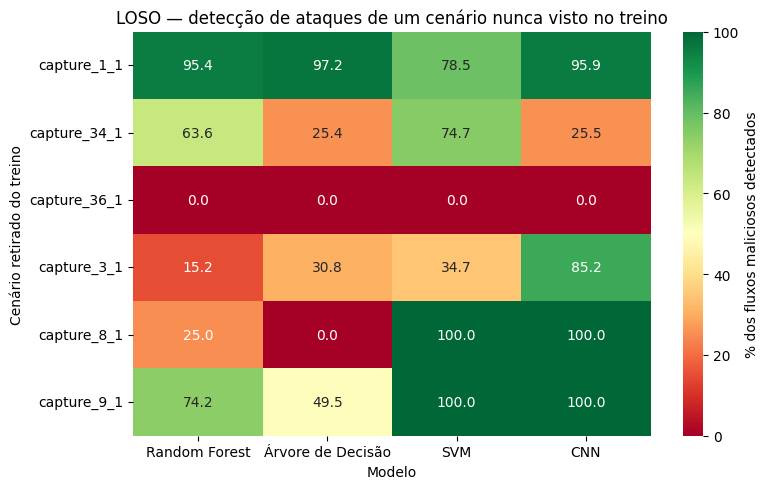

In [ ]:
# 7.3.3 — LOSO: tabelas-resumo e figura
ordem_modelos = ["Random Forest", "Árvore de Decisão", "SVM", "CNN"]

def resumo(tarefa, metrica):
    t = df_loso[df_loso["tarefa"] == tarefa].pivot(index="cenario_holdout", columns="modelo", values=metrica)
    t = t[[m for m in ordem_modelos if m in t.columns]]
    t.loc["MÉDIA"] = t.mean()
    return t.round(2 if metrica.endswith("%") else 4)

tabelas_loso = {   # título -> (tabela, arquivo CSV)
    "F1-macro (binário)":                                  (resumo("binário", "f1_macro"),             "loso_f1_binario.csv"),
    "Detecção do ataque nunca visto, % (binário)":         (resumo("binário", "deteccao_ataque_%"),    "loso_deteccao_binario.csv"),
    "Falso positivo nos benignos do cenário, % (binário)": (resumo("binário", "fp_benigno_cenario_%"), "loso_fp_benigno_cenario_binario.csv"),
    "F1-macro (multiclasse)":                              (resumo("multiclasse", "f1_macro"),         "loso_f1_multiclasse.csv"),
}
for titulo, (tabela, arquivo) in tabelas_loso.items():
    print(f"\n=== {titulo} ===")
    print(tabela.to_string())
    salvar_tabela(tabela.reset_index(), arquivo)

# Comparação com o teste "normal" (Seção 6.4): quanto cada modelo perde ao enfrentar um cenário inédito
f1_normal = df_tabela_final[df_tabela_final["tarefa"] == "binário"].copy()
f1_normal["modelo"] = f1_normal["algoritmo"].str.replace(r" \(.*\)", "", regex=True)
queda = pd.DataFrame({
    "f1_teste_normal": f1_normal.set_index("modelo")["f1_macro"],
    "f1_medio_loso": tabelas_loso["F1-macro (binário)"][0].loc["MÉDIA"],
}).reindex(ordem_modelos)
queda["queda_pontos"] = (queda["f1_teste_normal"] - queda["f1_medio_loso"]).round(4)
print("\n=== F1 binário: teste normal x LOSO ===")
print(queda.round(4).to_string())
salvar_tabela(queda.round(4).rename_axis("modelo").reset_index(), "loso_queda_vs_teste_normal.csv")

# Figura: taxa de detecção do ataque nunca visto (cenário x modelo)
deteccao = tabelas_loso["Detecção do ataque nunca visto, % (binário)"][0].drop(index="MÉDIA")
plt.figure(figsize=(8, 5))
sns.heatmap(deteccao, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100,
            cbar_kws={"label": "% dos fluxos maliciosos detectados"})
plt.title("LOSO — detecção de ataques de um cenário nunca visto no treino")
plt.xlabel("Modelo"); plt.ylabel("Cenário retirado do treino")
plt.tight_layout(); salvar_figura("loso_deteccao_heatmap.png"); plt.show()

In [ ]:
# 7.4 — Teste com distribuição NATURAL das classes (sem teto de amostragem)
# Amostra ~30 mil linhas do bruto na proporção real de cada classe, remove as que já
# existem no treino e avalia os modelos binários já treinados.
# Importante: a codificação usa o vocabulário de 'history' aprendido no pipeline principal.
TAMANHO_TESTE_NATURAL = 30_000
total_bruto = sum(CONTAGENS_BRUTO.values())
hashes_treino = set(pd.util.hash_pandas_object(X_treino, index=False))
rng = np.random.default_rng(RANDOM_STATE)

def codificar_como_treino(df_bruto):
    X_ext, y_bin_ext, _ = separar_X_y(preprocessar_features(df_bruto, CATEGORIAS_HISTORY)[0])
    X_ext = X_ext.reindex(columns=X_treino.columns, fill_value=0).astype(X_treino.dtypes.to_dict())
    return X_ext, y_bin_ext

partes = []
for classe, total in CONTAGENS_BRUTO.items():
    n_alvo = round(TAMANHO_TESTE_NATURAL * total / total_bruto)
    if n_alvo == 0:
        print(f"{classe}: proporção natural resulta em 0 exemplos -- pulando")
        continue
    df_classe = amostrar_classe_bruto(dataset_bruto, classe, min(1.0, n_alvo * 1.5 / total), rng)
    if df_classe.empty:
        continue
    X_tmp, _ = codificar_como_treino(df_classe)
    nao_visto = (~pd.util.hash_pandas_object(X_tmp, index=False).isin(hashes_treino)).values
    df_classe = df_classe.loc[nao_visto].reset_index(drop=True)
    if len(df_classe) > n_alvo:
        df_classe = df_classe.sample(n=n_alvo, random_state=RANDOM_STATE)
    print(f"{classe}: alvo={n_alvo} | obtido após remover overlap com o treino={len(df_classe)}")
    partes.append(df_classe)
    gc.collect()

df_bruto_natural = pd.concat(partes, ignore_index=True)
del partes; gc.collect()
X_teste_natural, y_bin_teste_natural = codificar_como_treino(df_bruto_natural)
print("\nDistribuição do teste natural:")
print(rotulo_multiclasse(df_bruto_natural["detailed-label"]).value_counts())
del df_bruto_natural

X_teste_natural_norm = X_teste_natural.copy()
X_teste_natural_norm[COLUNAS_NUMERICAS] = scaler.transform(X_teste_natural[COLUNAS_NUMERICAS])

resultados_dist_natural = []
for nome, modelo in {"Random Forest": RF_FINAL["binário"][0], "Árvore de Decisão": DT_FINAL["binário"][0],
                     f"SVM ({SVM_FINAL['binário'][0]})": SVM_FINAL["binário"][1],
                     "CNN": cnn_binario_final}.items():
    y_pred = modelo.predict(X_teste_natural_norm)
    print(f"\n=== {nome} — teste com distribuição natural ===")
    print(classification_report(y_bin_teste_natural, y_pred, digits=4, zero_division=0))
    resultados_dist_natural.append({"modelo": nome,
                                    "f1_macro": f1_score(y_bin_teste_natural, y_pred, average="macro")})

df_dist_natural = pd.DataFrame(resultados_dist_natural).round(4)
print(df_dist_natural.to_string(index=False))
salvar_tabela(df_dist_natural, "resultados_distribuicao_natural.csv")

okiru: alvo=19262 | obtido após remover overlap com o treino=0
partofahorizontalportscan: alvo=9952 | obtido após remover overlap com o treino=9952
benign: alvo=714 | obtido após remover overlap com o treino=297
c&c-heartbeat: alvo=22 | obtido após remover overlap com o treino=10
c&c: alvo=21 | obtido após remover overlap com o treino=6
ddos: alvo=20 | obtido após remover overlap com o treino=1
attack: alvo=8 | obtido após remover overlap com o treino=6

Distribuição do teste natural:
detailed-label
partofahorizontalportscan    9952
benign                        297
c&c-heartbeat                  10
c&c                             6
attack                          6
ddos                            1
Name: count, dtype: Int64

=== Random Forest — teste com distribuição natural ===
              precision    recall  f1-score   support

      benign     0.9867    1.0000    0.9933       297
   malicious     1.0000    0.9996    0.9998      9975

    accuracy                         0.9996  

## 8. Experimento: a representação das portas

**Motivação.** Dois resultados apontam para o mesmo mecanismo:
- **Seção 6.7:** as árvores dependem fortemente das portas (~45% da importância). Elas acertam quase tudo no teste normal, onde SVM e CNN confundem classes cujas portas viram números parecidos depois da padronização.
- **Seção 7.3:** no LOSO, a relação **se inverte**. SVM e CNN detectam em média 65–68% dos ataques inéditos; as árvores, 34–46%.

**Hipótese.** As árvores *memorizam* valores exatos de porta. Isso é ótimo para ataques conhecidos e ruim para ataques novos. SVM e CNN tratam a porta como grandeza contínua e "borram" essa informação: perdem precisão, mas generalizam melhor.

**Teste da hipótese.** Duas adaptações, avaliadas no teste normal e no LOSO binário:
1. **RF e AD sem as portas:** se a hipótese vale, perdem um pouco no teste normal e **ganham** no LOSO.
2. **CNN com portas categóricas:** one-hot das portas com ≥ `PORTAS_LIMIAR` ocorrências no treino, mais a categoria "outras". O vocabulário é aprendido só no treino; no LOSO, só no treino da rodada. Se a hipótese vale, a CNN **ganha** no teste normal e **perde** no LOSO.

Hiperparâmetros iguais aos dos modelos finais; só a representação das portas muda. O SVM ficou fora por custo computacional (mais de 3 h de Colab). A CNN representa a família de modelos "suaves". Todas as predições ficam em cache em `resultados/loso/`.

Este experimento responde ao objetivo específico de verificar se os algoritmos *"demandam adaptações metodológicas"* no contexto IoT.

In [ ]:
# 8.1 — Representações das portas e funções do experimento
COLUNAS_NUMERICAS_SEM_PORTA = [c for c in COLUNAS_NUMERICAS if c not in COLUNAS_PORTA]


def sem_portas(X_tr, X_te):
    X_tr_n, X_te_n, _ = normalizar(X_tr.drop(columns=COLUNAS_PORTA), X_te.drop(columns=COLUNAS_PORTA),
                                   COLUNAS_NUMERICAS_SEM_PORTA)
    return X_tr_n, X_te_n


def vocabulario_portas(X_tr):
    vocab = {}
    for col in COLUNAS_PORTA:
        contagem = X_tr[col].value_counts()
        vocab[col] = sorted(int(p) for p in contagem[contagem >= PORTAS_LIMIAR].index)
    return vocab


def portas_categoricas(X_tr, X_te):
    """One-hot das portas frequentes NO TREINO + 'outras'; o restante é normalizado como antes."""
    vocab = vocabulario_portas(X_tr)

    def codificar(X):
        partes = [X.drop(columns=COLUNAS_PORTA)]
        for col, frequentes in vocab.items():
            valores = np.where(X[col].isin(frequentes), X[col].astype(str), "outras")
            categorias = pd.Categorical(valores, categories=[str(p) for p in frequentes] + ["outras"])
            partes.append(pd.get_dummies(categorias, prefix=col, dtype="int8").set_axis(X.index))
        return pd.concat(partes, axis=1)

    X_tr_n, X_te_n, _ = normalizar(codificar(X_tr), codificar(X_te), COLUNAS_NUMERICAS_SEM_PORTA)
    return X_tr_n, X_te_n


def prever_rf(X_tr, y_tr, X_te, y_estrat, tarefa):
    return clone(RF_FINAL[tarefa][0]).fit(X_tr, y_tr).predict(X_te)

def prever_dt(X_tr, y_tr, X_te, y_estrat, tarefa):
    return clone(DT_FINAL[tarefa][0]).fit(X_tr, y_tr).predict(X_te)

# nome -> (modelo original na Seção 6/7, slug, transformação, função de treino+predição)
VARIANTES_PORTAS = {
    "RF sem portas":          ("Random Forest",     "rf",  "semportas",              sem_portas,         prever_rf),
    "AD sem portas":          ("Árvore de Decisão", "dt",  "semportas",              sem_portas,         prever_dt),
    "CNN portas categóricas": ("CNN",               "cnn", f"portascat{PORTAS_LIMIAR}", portas_categoricas, cnn_loso),
}


def chave_variante(slug, tarefa):
    if slug == "cnn":
        params, seed = config_cnn(tarefa)
        return id_config({**params, "seed": seed, "epocas_max": CNN_EPOCAS_MAX, "paciencia": CNN_PACIENCIA})
    modelo = (RF_FINAL if slug == "rf" else DT_FINAL)[tarefa][0]
    return id_config({k: str(v) for k, v in modelo.get_params().items()})


def metricas_binarias(y_te, pred, do_cenario):
    pred_mal = pred == "malicious"
    return {"deteccao_ataque_%":     pct((y_te == "malicious") & do_cenario, pred_mal),
            "fp_benigno_cenario_%":  pct((y_te == "benign") & do_cenario, pred_mal),
            "fp_benigno_honeypot_%": pct(~do_cenario, pred_mal)}


vocab = vocabulario_portas(X_treino)
print(f"Portas que viram categoria própria (>= {PORTAS_LIMIAR} ocorrências no treino):")
for col, portas in vocab.items():
    print(f"  {col}: {len(portas)} portas -> {portas}")
n_atrib = X_treino.shape[1] - len(COLUNAS_PORTA) + sum(len(p) + 1 for p in vocab.values())
print(f"Atributos da CNN com portas categóricas: {n_atrib} -> matriz {formato_para(n_atrib)}")

Portas que viram categoria própria (>= 500 ocorrências no treino):
  id.resp_p: 15 portas -> [1, 22, 23, 50, 53, 81, 123, 2323, 6667, 6881, 8080, 9527, 51413, 57722, 59353]
  id.orig_p: 4 portas -> [3, 123, 29930, 43763]
Atributos da CNN com portas categóricas: 61 -> matriz (7, 9)


In [ ]:
# 8.2 — Teste normal (mesmo split 70/30 da Seção 3)
linhas_normal = []
for nome, (_, slug, tipo, transformar, prever) in VARIANTES_PORTAS.items():
    X_tr_v, X_te_v = transformar(X_treino, X_teste)
    for tarefa, y_tr, y_te in [("binário", y_bin_treino, y_bin_teste), ("multiclasse", y_multi_treino, y_multi_teste)]:
        y_tr, y_te = y_tr.astype(str).to_numpy(), y_te.astype(str).to_numpy()
        nome_cache = f"variante_{slug}_{tipo}_{SLUG_TAREFA[tarefa]}_normal_{chave_variante(slug, tarefa)}"
        pred, tempo, do_cache = loso_predicoes(
            nome_cache, lambda: prever(X_tr_v, y_tr, X_te_v, y_multi_treino.astype(str).to_numpy(), tarefa))
        f1 = f1_score(y_te, pred, average="macro", zero_division=0)
        linhas_normal.append({"variante": nome, "tarefa": tarefa, "f1_macro": f1})
        print(f"[{tarefa:11s}] {nome:23s} F1-macro={f1:.4f}{'  (cache)' if do_cache else f'  ({tempo:.0f}s)'}")
        if tarefa == "multiclasse":
            print(classification_report(y_te, pred, digits=4, zero_division=0))

df_portas_normal = pd.DataFrame(linhas_normal)
salvar_tabela(df_portas_normal.round(4), "portas_teste_normal.csv")

[binário    ] RF sem portas           F1-macro=0.8286  (7s)
[multiclasse] RF sem portas           F1-macro=0.4581  (21s)
                           precision    recall  f1-score   support

                   attack     0.9972    0.9978    0.9975      1789
                   benign     0.9881    0.7641    0.8618     36986
                      c&c     0.5426    0.3159    0.3993      3248
            c&c-heartbeat     0.6429    0.3145    0.4224      4706
                     ddos     0.0060    1.0000    0.0119        67
                    okiru     0.0631    0.0699    0.0663       186
partofahorizontalportscan     0.4146    0.4858    0.4474      5990

                 accuracy                         0.6710     52972
                macro avg     0.5221    0.5640    0.4581     52972
             weighted avg     0.8611    0.6710    0.7483     52972

[binário    ] AD sem portas           F1-macro=0.8281  (1s)
[multiclasse] AD sem portas           F1-macro=0.4653  (1s)
                   

In [ ]:
# 8.3 — LOSO binário das variantes (mesma partição da Seção 7.3)
linhas_loso_portas = []
for cenario in cenarios_maliciosos:
    idx_tr = origem_cenario_dedup.index[origem_cenario_dedup.isin([c for c in cenarios_maliciosos if c != cenario])]
    idx_te = origem_cenario_dedup.index[origem_cenario_dedup == cenario]
    idx_tr, idx_te = idx_tr.append(idx_ben_tr), idx_te.append(idx_ben_te)
    do_cenario = (origem_cenario_dedup.loc[idx_te] == cenario).to_numpy()
    y_tr = y_binario_dedup.loc[idx_tr].astype(str).to_numpy()
    y_te = y_binario_dedup.loc[idx_te].astype(str).to_numpy()
    y_estrat = y_multiclasse_dedup.loc[idx_tr].astype(str).to_numpy()
    print(f"\n######## {cenario} fora do treino")

    for nome, (_, slug, tipo, transformar, prever) in VARIANTES_PORTAS.items():
        X_tr_v, X_te_v = transformar(X_dedup.loc[idx_tr], X_dedup.loc[idx_te])
        nome_cache = f"variante_{slug}_{tipo}_binario_{cenario}_{chave_variante(slug, 'binário')}"
        pred, tempo, do_cache = loso_predicoes(
            nome_cache, lambda: prever(X_tr_v, y_tr, X_te_v, y_estrat, "binário"))
        linha = {"cenario_holdout": cenario, "variante": nome,
                 "f1_macro": f1_score(y_te, pred, average="macro", zero_division=0),
                 **metricas_binarias(y_te, pred, do_cenario)}
        linhas_loso_portas.append(linha)
        print(f"  {nome:23s} F1={linha['f1_macro']:.4f} | detecção={linha['deteccao_ataque_%']:.1f}% "
              f"| FP cenário={linha['fp_benigno_cenario_%']:.1f}%{'  (cache)' if do_cache else f'  ({tempo:.0f}s)'}")
    gc.collect()

df_loso_portas = pd.DataFrame(linhas_loso_portas)
salvar_tabela(df_loso_portas.round(4), "portas_loso_binario.csv")


######## capture_1_1 fora do treino
  RF sem portas           F1=0.6161 | detecção=95.9% | FP cenário=29.6%  (5s)
  AD sem portas           F1=0.6163 | detecção=95.9% | FP cenário=29.6%  (0s)
  CNN portas categóricas  F1=0.6583 | detecção=62.2% | FP cenário=14.8%  (25s)

######## capture_34_1 fora do treino
  RF sem portas           F1=0.8319 | detecção=87.9% | FP cenário=8.2%  (9s)
  AD sem portas           F1=0.9591 | detecção=98.3% | FP cenário=7.9%  (1s)
  CNN portas categóricas  F1=0.1342 | detecção=0.1% | FP cenário=4.6%  (54s)

######## capture_36_1 fora do treino
  RF sem portas           F1=0.9105 | detecção=96.3% | FP cenário=0.1%  (8s)
  AD sem portas           F1=0.9117 | detecção=96.4% | FP cenário=0.0%  (1s)
  CNN portas categóricas  F1=0.0807 | detecção=0.0% | FP cenário=0.1%  (139s)

######## capture_3_1 fora do treino
  RF sem portas           F1=0.4172 | detecção=22.9% | FP cenário=10.2%  (10s)
  AD sem portas           F1=0.6945 | detecção=60.8% | FP cenário=6.4%  (

           modelo             representacao  f1_normal_binario  f1_normal_multiclasse  f1_loso_binario_medio  deteccao_loso_media_%
    Random Forest original (porta numérica)             0.9983                 0.9950                 0.4654                45.5600
    Random Forest                sem portas             0.8286                 0.4581                 0.7800                83.8226
Árvore de Decisão original (porta numérica)             0.9990                 0.9973                 0.3483                33.8100
Árvore de Decisão                sem portas             0.8281                 0.4653                 0.8499                91.9049
              CNN original (porta numérica)             0.9713                 0.7153                 0.6475                67.7700
              CNN        portas categóricas             0.9937                 0.8059                 0.3297                18.6274
              SVM     original (referência)             0.9554              

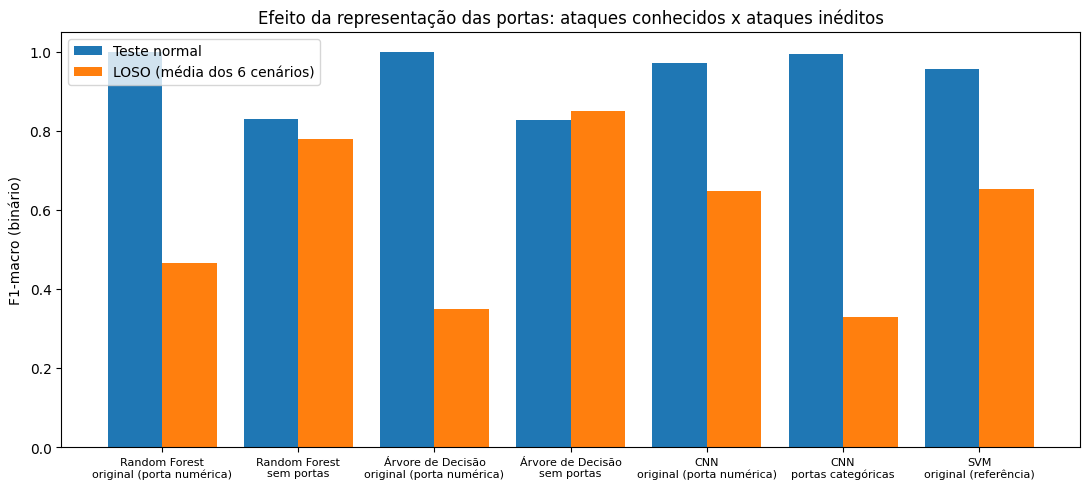

In [ ]:
# 8.4 — Resumo: original x variante, no teste normal e no LOSO
f1_loso_orig = tabelas_loso["F1-macro (binário)"][0].loc["MÉDIA"]
det_loso_orig = tabelas_loso["Detecção do ataque nunca visto, % (binário)"][0].loc["MÉDIA"]
tab_final = df_tabela_final.assign(modelo=df_tabela_final["algoritmo"].str.replace(r" \(.*\)", "", regex=True))

def f1_normal_orig(modelo, tarefa):
    return tab_final[(tab_final["modelo"] == modelo) & (tab_final["tarefa"] == tarefa)]["f1_macro"].iloc[0]

linhas = []
for nome, (original, *_ ) in VARIANTES_PORTAS.items():
    loso_v = df_loso_portas[df_loso_portas["variante"] == nome]
    normal_v = df_portas_normal[df_portas_normal["variante"] == nome].set_index("tarefa")["f1_macro"]
    linhas.append({"modelo": original, "representacao": "original (porta numérica)",
                   "f1_normal_binario": f1_normal_orig(original, "binário"),
                   "f1_normal_multiclasse": f1_normal_orig(original, "multiclasse"),
                   "f1_loso_binario_medio": f1_loso_orig[original], "deteccao_loso_media_%": det_loso_orig[original]})
    linhas.append({"modelo": original, "representacao": nome.split(" ", 1)[1],
                   "f1_normal_binario": normal_v["binário"], "f1_normal_multiclasse": normal_v["multiclasse"],
                   "f1_loso_binario_medio": loso_v["f1_macro"].mean(),
                   "deteccao_loso_media_%": loso_v["deteccao_ataque_%"].mean()})
linhas.append({"modelo": "SVM", "representacao": "original (referência)",
               "f1_normal_binario": f1_normal_orig("SVM", "binário"),
               "f1_normal_multiclasse": f1_normal_orig("SVM", "multiclasse"),
               "f1_loso_binario_medio": f1_loso_orig["SVM"], "deteccao_loso_media_%": det_loso_orig["SVM"]})

df_resumo_portas = pd.DataFrame(linhas).round(4)
print(df_resumo_portas.to_string(index=False))
salvar_tabela(df_resumo_portas, "portas_resumo.csv")

# Detecção no LOSO por cenário: original x variante
det_var = df_loso_portas.pivot(index="cenario_holdout", columns="variante", values="deteccao_ataque_%")
det_orig = tabelas_loso["Detecção do ataque nunca visto, % (binário)"][0].drop(index="MÉDIA")
comparativo = pd.concat({"RF": det_orig["Random Forest"], "RF sem portas": det_var["RF sem portas"],
                         "AD": det_orig["Árvore de Decisão"], "AD sem portas": det_var["AD sem portas"],
                         "CNN": det_orig["CNN"], "CNN portas categ.": det_var["CNN portas categóricas"]}, axis=1)
print("\nDetecção do ataque nunca visto (%), por cenário:")
print(comparativo.round(1).to_string())
salvar_tabela(comparativo.round(2).reset_index(), "portas_loso_deteccao_por_cenario.csv")

# Figura: F1 no teste normal x F1 médio no LOSO (binário)
fig_df = df_resumo_portas.assign(rotulo=df_resumo_portas["modelo"] + "\n" + df_resumo_portas["representacao"])
x = np.arange(len(fig_df))
plt.figure(figsize=(11, 5))
plt.bar(x - 0.2, fig_df["f1_normal_binario"], 0.4, label="Teste normal")
plt.bar(x + 0.2, fig_df["f1_loso_binario_medio"], 0.4, label="LOSO (média dos 6 cenários)")
plt.xticks(x, fig_df["rotulo"], fontsize=8)
plt.ylabel("F1-macro (binário)"); plt.ylim(0, 1.05); plt.legend()
plt.title("Efeito da representação das portas: ataques conhecidos x ataques inéditos")
plt.tight_layout(); salvar_figura("portas_normal_vs_loso.png"); plt.show()